# LV cavity, myocardium and left atrium — **prompt-free** segmentation → original-pixel ROIs, each region in its own frame, extraction (v12)

**This notebook no longer uses UltraSam (or any prompt-based model).** The segmenter is an **nnU-Net trained on CAMUS** that receives **only the ultrasound frame** — no boxes, no points, no reference/support frames, no text.

| | |
|---|---|
| **Method run in this notebook** | **nnU-Net** — a pixel-wise U-Net framework (it labels every pixel; it is *not* a graph network). The network was trained on CAMUS by the authors of the paper below and released as an ONNX file. **No graph network (GCN) is used here.** |
| **Paper that trained and released these weights** | G. Van De Vyver, S. Thomas, G. Ben-Yosef, S. H. Olaisen, H. Dalen, L. Løvstakken, E. Smistad — *Towards Robust Cardiac Segmentation using Graph Convolutional Networks*, **IEEE Access (2024)**, https://ieeexplore.ieee.org/document/10458930 · arXiv:2310.01210 |
| **GitHub — nnU-Net (the method we run)** | https://github.com/MIC-DKFZ/nnUNet (DKFZ / Helmholtz Imaging) |
| **GitHub — the paper's repos** | https://github.com/GillesVanDeVyver/GCN_multistructure (MIT; code of the paper's *graph* network and its training) · https://github.com/gillesvntnu/GCN_UNET_agreement_demo (demo that runs the graph network and the nnU-Net ONNX side by side). We use neither repo's code, only the released nnU-Net weights. |
| **Weights** | https://huggingface.co/gillesvdv/nnunet_camus_cv1_onnx (CC-BY-4.0 — **cite the paper when you use them**) |
| **Training data** | CAMUS: 500 patients, apical 2- and 4-chamber views, GE Vivid E95; labels LV cavity, myocardium, left atrium |
| **Output** | 0 = background · **1 = LV cavity · 2 = myocardium · 3 = left atrium**, on the same frame |
| **nnU-Net paper** | Isensee et al., *Nature Methods* 18:203–211 (2021), https://doi.org/10.1038/s41592-020-01008-z |

### Run order (top to bottom; no GPU needed): A, A2, B, P1, P2, F, **T**, G, H
| Stage | What happens |
|---|---|
| A | Load frames, unify grey scale, remove ECG/markers/text, find the fan |
| **A2** | View check: are all frames the same recording and view? Only the main recording is segmented |
| B | Helper images/functions used by the checks (no prompts) |
| **P1 → P2** | **Prompt-free segmentation**: download the model, segment every frame, build the label maps |
| **F** | Final masks, **automatic sanity checks (PASS / WARN)**, ED/ES, measurements over the heartbeat |
| **T** | **GLCM texture analysis** (Haralick features) of LV cavity, myocardium and left atrium on every frame (original pixel values, inside the masks) |
| G | Original-pixel ROIs, each region in its own frame, view/anatomy checks, extraction |
| H | Save everything + one zip (includes `CITATION.txt` and `run_summary.json`) |

**Honest limits.** The model was trained on CAMUS-style apical views from one scanner type; on other machines or crops quality can drop. Frames are segmented **independently** (no temporal smoothing), so masks can flicker. The checks in stage F test *plausibility*, not accuracy: for accuracy, have an expert outline 2–3 frames and compute Dice against them.

## A. Load and standardise the frames

In [2]:
import os, glob, zipfile, json, shutil, subprocess, time, warnings
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.spatial import cKDTree
from scipy.signal import savgol_filter, find_peaks
warnings.filterwarnings('ignore'); plt.rcParams['figure.dpi'] = 110

DATA_DIR = '/content/frames_raw'
if not glob.glob(f'{DATA_DIR}/**/*.png', recursive=True):
    from google.colab import files
    print('Select frames.zip'); up = files.upload()
    os.makedirs(DATA_DIR, exist_ok=True)
    with zipfile.ZipFile(list(up.keys())[0]) as z: z.extractall(DATA_DIR)
FILES = sorted(glob.glob(f'{DATA_DIR}/**/*.png', recursive=True))
print(len(FILES), 'frames:', os.path.basename(FILES[0]), '...', os.path.basename(FILES[-1]))

# ---------------- Config ----------------
WORK   = '/content/echo_work'                 # everything we create goes here
INPUT_MODE = 'clean'           # 'clean' = grey + overlays removed (recommended) | 'despeckled' = additionally NLM-filtered
FPS        = None              # set the frame rate (Hz) if you know it -> time axis in seconds
PROCESS_CLIPS = 'main'          # 'main' = only the main recording (the clip detected in stage A2) | 'all' = every frame (other recordings use the main clip's geometry: unreliable)
SAVE_BINARY_MASKS = False       # True = ALSO save the old white-on-black binary masks (masks_LV/, masks_MYO/, masks_LA/)
BAR = (slice(25,100), slice(612,626))   # colour-bar location (rows, cols) in THESE frames
os.makedirs(WORK, exist_ok=True)

Select frames.zip


Saving frames.zip to frames.zip
55 frames: frame_0000.png ... frame_0054.png


In [3]:
def load_rgb(path):
    im = cv2.imread(path, cv2.IMREAD_UNCHANGED)[..., :3]      # drop alpha (all zeros in the RGBA frames)
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

RGB = [load_rgb(f) for f in FILES]
H, W = RGB[0].shape[:2]; print('frame size (H, W):', H, W)

def is_gray_frame(rgb):
    b = rgb[BAR].astype(float).mean(1)                 # colours of the on-screen colour bar
    return np.abs(b[:,0]-b[:,1]).mean() < 8            # grey bar -> grey frame
GRAY_FLAG = np.array([is_gray_frame(r) for r in RGB])
REF_BAR = next(r for r, g in zip(RGB, GRAY_FLAG) if g)[BAR].astype(float).mean(1).mean(1)

def to_gray(rgb):
    """Grey frame -> luminance. Colour-mapped frame -> undo the colour map using the colour bar."""
    if is_gray_frame(rgb): return rgb.astype(np.float32).mean(2)
    bar = rgb[BAR].astype(float).mean(1)
    lut, vals = np.vstack([bar, [0,0,0]]), np.append(REF_BAR, 0)
    idx = cKDTree(lut).query(rgb.reshape(-1,3).astype(float))[1]
    return vals[idx].reshape(rgb.shape[:2]).astype(np.float32)

G = np.stack([to_gray(r) for r in RGB])
print('grey frames:', int(GRAY_FLAG.sum()), '| colour-mapped frames:', int((~GRAY_FLAG).sum()))

# sequence integrity: neighbouring frames of ONE clip are highly correlated
crop = (slice(40,300), slice(120,520))
corr = np.array([np.corrcoef(G[i][crop].ravel(), G[i+1][crop].ravel())[0,1] for i in range(len(G)-1)])
breaks = [i+1 for i in np.where((corr < 0.8) | (GRAY_FLAG[:-1] != GRAY_FLAG[1:]))[0]]
bounds = [0] + breaks + [len(G)]
SEGMENTS = [(bounds[k], bounds[k+1]) for k in range(len(bounds)-1)]
MAIN = max(SEGMENTS, key=lambda s: s[1]-s[0]); s0, s1 = MAIN
print('clips (start, end):', SEGMENTS, '-> main clip used for time analysis:', MAIN)

frame size (H, W): 422 636
grey frames: 50 | colour-mapped frames: 5
clips (start, end): [(0, np.int64(50)), (np.int64(50), 55)] -> main clip used for time analysis: (0, np.int64(50))


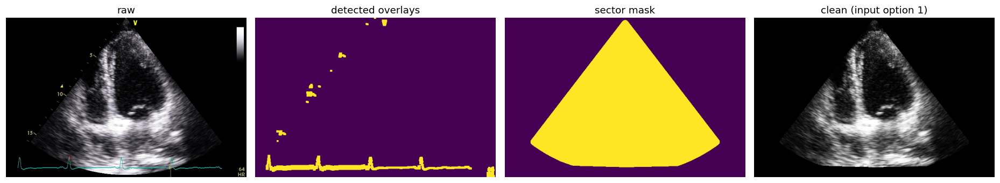

In [4]:
def overlay_mask(frames, thr=40):          # coloured burned-in graphics (ECG trace, yellow markers, text)
    m = np.zeros(frames[0].shape[:2], bool)
    for f in frames: m |= (f.max(2).astype(int) - f.min(2).astype(int)) > thr
    return cv2.dilate(m.astype(np.uint8), np.ones((5,5), np.uint8)).astype(bool)

def sector_mask(stack, ov):                # fan-shaped region that actually contains ultrasound data
    m = (stack.mean(0) > 4) & ~ov
    m[:, 600:] = False                     # colour bar / heart-rate text column
    m = cv2.morphologyEx(m.astype(np.uint8), cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(15,15)))
    lab, n = ndi.label(m); big = np.argmax(ndi.sum(m, lab, range(1,n+1))) + 1
    hull = cv2.convexHull(np.column_stack(np.where((lab==big).T)).astype(np.int32))
    out = np.zeros(m.shape, np.uint8); cv2.fillConvexPoly(out, hull, 1); return out.astype(bool)

def inpaint(img, mask):
    return cv2.inpaint(np.clip(img,0,255).astype(np.uint8), mask.astype(np.uint8), 3, cv2.INPAINT_TELEA).astype(np.float32)

OV = overlay_mask([r for r, g in zip(RGB, GRAY_FLAG) if g])
SM = sector_mask(G[GRAY_FLAG], OV)
P  = np.stack([inpaint(g, OV & SM) * SM for g in G])           # clean grey frames, sector only
S  = np.stack([cv2.fastNlMeansDenoising(np.clip(p,0,255).astype(np.uint8), None, h=15, templateWindowSize=7, searchWindowSize=21).astype(np.float32) for p in P])

i = (s0+s1)//2
fig, ax = plt.subplots(1, 4, figsize=(17,4))
for a, im, t in zip(ax, [RGB[i], OV, SM, P[i]], ['raw', 'detected overlays', 'sector mask', 'clean (input option 1)']):
    a.imshow(im, cmap='gray' if im.ndim==2 and t.startswith('clean') else None); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.show()

## A2. View check: are all frames the same recording and view?
Frames of **one** acquisition keep the same fan shape, position and grey scale. A frame with a **colour map**, a **different fan outline** or a **low similarity** to the main clip belongs to another recording (possibly another view or zoom). The prompts of the next stage are built from the main clip, so by default only that clip is processed. The picture shows the first frame of each clip (raw, converted to grey, and contrast-enhanced for viewing).

,clip,frames,n_frames,colour_map,fan_x,fan_y,similarity_to_main_clip,role
0,0,0-49,50,no,68-567,6-415,1.00,MAIN clip (processed)
1,1,50-54,5,YES (teal),100-521,37-416,0.77,other recording


VIEW CHECK: frames 50-54 are a DIFFERENT recording (colour map / different fan outline / low similarity). They are NOT segmented.
To process them anyway use PROCESS_CLIPS = "all" (unreliable), or run this notebook again on a zip that contains only those frames.


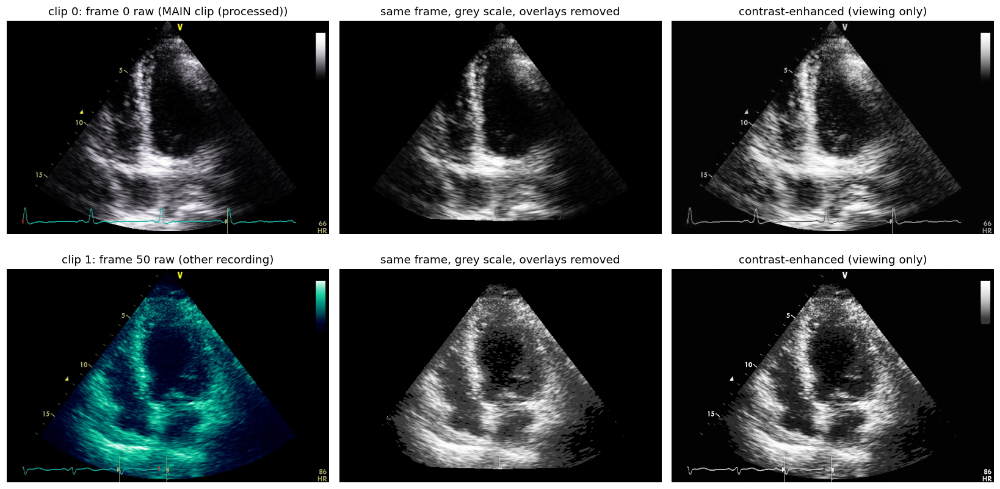

In [5]:
PROCESS_CLIPS = globals().get('PROCESS_CLIPS', 'main')
rows = []; main_mean = G[s0:s1].mean(0)
for ci, (a, b) in enumerate(SEGMENTS):
    sec_ = G[a:b].mean(0) > 4; sec_[:, 600:] = False
    sec_ = cv2.morphologyEx(sec_.astype(np.uint8), cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))) > 0
    ys, xs = np.where(sec_)
    cc = np.corrcoef(G[a:b].mean(0)[crop].ravel(), main_mean[crop].ravel())[0, 1]
    rows.append(dict(clip=ci, frames=f'{a}-{b-1}', n_frames=int(b-a), colour_map='no' if GRAY_FLAG[a:b].all() else 'YES (teal)', fan_x=f'{xs.min()}-{xs.max()}', fan_y=f'{ys.min()}-{ys.max()}',
                     similarity_to_main_clip=round(float(cc), 2), role='MAIN clip (processed)' if (a, b) == (s0, s1) else ('other recording' )))
VIEW_CLIPS = pd.DataFrame(rows); display(VIEW_CLIPS)
PROC_FRAMES = list(range(s0, s1)) if PROCESS_CLIPS == 'main' else list(range(len(P)))
others = [r for r in rows if r['role'] != 'MAIN clip (processed)']
if others and PROCESS_CLIPS == 'main':
    print(f'VIEW CHECK: frames {", ".join(r["frames"] for r in others)} are a DIFFERENT recording (colour map / different fan outline / low similarity). They are NOT segmented.')
    print('To process them anyway use PROCESS_CLIPS = "all" (unreliable), or run this notebook again on a zip that contains only those frames.')
else: print(f'VIEW CHECK: processing frames {PROC_FRAMES[0]}-{PROC_FRAMES[-1]} ({len(PROC_FRAMES)} frames).')
cl_v = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(6, 6))
fig, ax = plt.subplots(len(SEGMENTS), 3, figsize=(15, 3.9*len(SEGMENTS)), squeeze=False)
for ci, (a, b) in enumerate(SEGMENTS):
    ax[ci, 0].imshow(RGB[a]); ax[ci, 0].set_title(f'clip {ci}: frame {a} raw ({rows[ci]["role"]})')
    ax[ci, 1].imshow(np.clip(P[a], 0, 255), cmap='gray', vmin=0, vmax=255); ax[ci, 1].set_title('same frame, grey scale, overlays removed')
    ax[ci, 2].imshow(cl_v.apply(np.clip(G[a], 0, 255).astype(np.uint8)), cmap='gray'); ax[ci, 2].set_title('contrast-enhanced (viewing only)')
    [x.axis('off') for x in ax[ci]]
plt.tight_layout(); plt.show()

## B. Reference images and helper functions (no prompts)
Only used by the quality checks and the information check of the left atrium. Nothing here is given to the segmentation model.

In [6]:
MEAN = P[s0:s1].mean(0)                                          # temporal mean of the main clip (for display / checks only)
EDGE_DIST = ndi.distance_transform_edt(SM)                       # distance of every pixel to the border of the fan (the border is a shadow zone)

def info_stats(mask, img):                                       # how much information (echo signal) a region carries
    v = img[mask].astype(float)
    if v.size < 20: return dict(n_pixels=int(v.size), mean=np.nan, std=np.nan, near_black_pct=np.nan, entropy_bits=np.nan, median_edge_dist_px=np.nan)
    h, _ = np.histogram(v, bins=32, range=(0, 256)); p = h[h > 0] / h.sum()
    return dict(n_pixels=int(v.size), mean=round(v.mean(), 1), std=round(v.std(), 1), near_black_pct=round(100*(v < 6).mean(), 1),
                entropy_bits=round(float(-(p*np.log2(p)).sum()), 2), median_edge_dist_px=round(float(np.median(EDGE_DIST[mask])), 1))
print('helpers ready | main clip frames', s0, '-', s1 - 1, '| image size (H, W):', H, W)

helpers ready | main clip frames 0 - 49 | image size (H, W): 422 636


## P. Prompt-free segmentation (nnU-Net trained on CAMUS)
**P1** downloads the public ONNX model and segments every processed frame; **P2** turns the predictions into the notebook's label maps. The model input is **only the grey frame** (256×256); there is nothing else to give it.

**Class convention (CAMUS):** 0 = background, 1 = LV cavity, 2 = myocardium, 3 = left atrium. If the overlay shows swapped classes, set `LABEL_REMAP` in P2.

**Run order:** `A → A2 → B → P1 → P2 → F → T → G → H`. After *Restart runtime* run A, A2, B again first (P needs the frames and fan mask they create).

P1 also tries 4 input variants (z-score or 0–1 scaling, with or without left–right flip) on three frames and keeps the most anatomically plausible one. If all variants score the same, the model is insensitive to them and the choice does not matter.

In [7]:
# ---- P1. Prompt-free segmentation with the CAMUS nnU-Net (Van De Vyver et al., IEEE Access 2024) ----
import os, glob, re, zipfile, shutil, subprocess, sys
import numpy as np, cv2
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
_need = [n for n in ('P', 'SM', 'PROC_FRAMES') if n not in globals()]
if _need:
    raise RuntimeError(f"Stage P needs {_need} from the earlier stages. Run, in this order: stage A (load frames), A2 (view check), B (prompts/ROI), THEN P1 and P2. "
                       "(After 'Restart runtime' all earlier stages must be run again.)")
def _pip(*a): subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *a], check=False)
try: import onnxruntime as ort
except ImportError: _pip('onnxruntime'); import onnxruntime as ort
try: from huggingface_hub import hf_hub_download, list_repo_files
except ImportError: _pip('huggingface_hub'); from huggingface_hub import hf_hub_download, list_repo_files

PF_REPO = 'gillesvdv/nnunet_camus_cv1_onnx'     # public weights of the paper's nnU-Net (CC-BY-4.0, cite the paper)
PF_OUT  = '/content/promptfree_pred'            # one label PNG per processed frame goes here

def load_nnunet_session():
    files = [f for f in list_repo_files(PF_REPO) if f.lower().endswith('.onnx')]
    if not files: raise RuntimeError(f'no .onnx file found in {PF_REPO}')
    path = hf_hub_download(PF_REPO, files[0])
    prov = [p for p in ('CUDAExecutionProvider', 'CPUExecutionProvider') if p in ort.get_available_providers()]
    return ort.InferenceSession(path, providers=prov)

def _dim(v, default): return int(v) if isinstance(v, (int, np.integer)) else default

def prepare(frame, in_shape, norm, flip):
    n, c, h, w = [_dim(v, d) for v, d in zip(in_shape, (1, 1, 256, 256))]
    f = frame.astype(np.float32)
    if norm == 'unit': f = np.clip(f / (255.0 if f.max() > 1.5 else 1.0), 0, 1)
    else:              f = (f - f.mean()) / (f.std() + 1e-6)                 # nnU-Net default: per-image z-score
    if flip: f = f[:, ::-1]
    f = cv2.resize(np.ascontiguousarray(f), (w, h), interpolation=cv2.INTER_LINEAR)
    return np.repeat(f[None, None], c, axis=1).astype(np.float32)

def to_labels(out, shape, flip):
    a = np.asarray(out)
    if a.ndim == 4: a = a[0].argmax(0)                                         # (1, C, H, W) logits
    elif a.ndim == 3: a = a.argmax(0) if a.dtype.kind == 'f' else a[0]         # (C, H, W) logits or (1, H, W) labels
    a = cv2.resize(a.astype(np.uint8), (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)
    return np.ascontiguousarray(a[:, ::-1] if flip else a)

def clean_labels(a, sector):
    a = a.copy(); a[~sector] = 0
    for k in (1, 2, 3):                                                         # keep the largest piece of each structure
        m = a == k
        if not m.any(): continue
        lab, n = ndi.label(m)
        if n > 1: a[m & (lab != np.argmax(ndi.sum(m, lab, range(1, n+1))) + 1)] = 0
    for k in (1, 3):                                                            # cavities have no holes
        a[ndi.binary_fill_holes(a == k) & (a == 0)] = k
    return a

def plausibility(a, sector):
    fan = max(int(sector.sum()), 1); area = {k: (a == k).sum() / fan for k in (1, 2, 3)}
    s = sum(1.0 for k in (1, 2, 3) if area[k] > 0.003) + (1.0 if 0.01 < area[1] < 0.25 else 0.0)
    lv = a == 1
    if lv.any():
        ring = cv2.dilate(lv.astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool) & ~lv
        if ring.any(): s += float((a[ring] == 2).mean())                        # the LV cavity should be wrapped by myocardium
    return s

def segment(sess, frame, norm, flip):
    name = sess.get_inputs()[0].name
    return to_labels(sess.run(None, {name: prepare(frame, sess.get_inputs()[0].shape, norm, flip)})[0], frame.shape, flip)

def pick_config(sess, frames, sector):
    scores = {}
    for norm in ('zscore', 'unit'):
        for flip in (False, True):
            scores[(norm, flip)] = sum(plausibility(clean_labels(segment(sess, f, norm, flip), sector), sector) for f in frames)
    return max(scores, key=scores.get), scores

PF_SESS = load_nnunet_session()
print('model input :', PF_SESS.get_inputs()[0].name, PF_SESS.get_inputs()[0].shape, '| output:', PF_SESS.get_outputs()[0].shape)
probe = [P[PROC_FRAMES[i]] for i in np.linspace(0, len(PROC_FRAMES)-1, 3).astype(int)]
(PF_NORM, PF_FLIP), PF_SCORES = pick_config(PF_SESS, probe, SM)
print('plausibility per variant (max 5 per frame):', {f'{n}/{"flip" if f else "as-is"}': round(v/3, 2) for (n, f), v in PF_SCORES.items()})
print('chosen variant:', PF_NORM, 'with flip' if PF_FLIP else 'as-is')

shutil.rmtree(PF_OUT, ignore_errors=True); os.makedirs(PF_OUT)
for i, k in enumerate(PROC_FRAMES):
    cv2.imwrite(f'{PF_OUT}/pred_{i:04d}.png', clean_labels(segment(PF_SESS, P[k], PF_NORM, PF_FLIP), SM))
print(f'{len(PROC_FRAMES)} label maps written to {PF_OUT}  (1 LV cavity, 2 myocardium, 3 left atrium)')

nnunet_camus_cv1.onnx: reconstructing file:   0%|          |  0.00B /  134MB            

nnunet_camus_cv1.onnx: downloading bytes:           |  0.00B            

model input : input image 256x256 [1, 1, 256, 256] | output: [1, 4, 256, 256]
plausibility per variant (max 5 per frame): {'zscore/as-is': 4.85, 'zscore/flip': 4.85, 'unit/as-is': 4.85, 'unit/flip': 4.85}
chosen variant: unit with flip
50 label maps written to /content/promptfree_pred  (1 LV cavity, 2 myocardium, 3 left atrium)


prompt-free label maps: {'LV cavity px': 695165, 'myocardium px': 789400, 'left atrium px': 468199} | frames segmented: 50


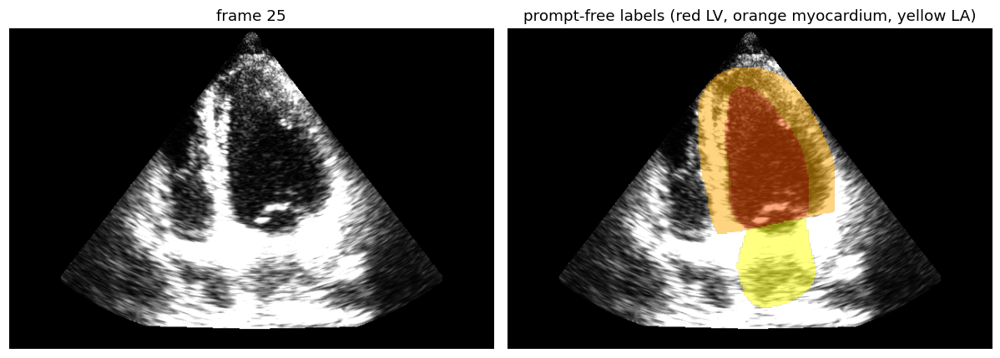

CHECK: the myocardium should wrap the LV cavity and the left atrium should lie below the LV base. If classes look swapped set LABEL_REMAP and run P2 again.


In [8]:
# ---- P2. Assemble the label map of every frame: 0 background, 1 LV cavity, 2 myocardium, 3 left atrium ----
import os, glob
import numpy as np, cv2
import matplotlib.pyplot as plt
_need = [n for n in ('P', 'SM', 'PROC_FRAMES', 'PF_OUT') if n not in globals()]
if _need: raise RuntimeError(f'Stage P2 needs {_need}: run stages A, A2, B and P1 first.')
LABEL_REMAP = globals().get('LABEL_REMAP', {0: 0, 1: 1, 2: 2, 3: 3})   # model value -> notebook value; change only if the overlay shows swapped classes
T_ = len(P)
files = sorted(glob.glob(f'{PF_OUT}/pred_*.png'))
if len(files) != len(PROC_FRAMES): raise RuntimeError(f'expected {len(PROC_FRAMES)} label maps in {PF_OUT}, found {len(files)}: run P1 again')
LAB = np.zeros((T_, H, W), np.uint8)
for k, f in zip(PROC_FRAMES, files):
    a = cv2.imread(f, cv2.IMREAD_UNCHANGED)
    if a.ndim == 3: a = a[..., 0]
    if a.shape != (H, W): a = cv2.resize(a, (W, H), interpolation=cv2.INTER_NEAREST)
    out = np.zeros(a.shape, np.uint8)
    for src_v, dst_v in LABEL_REMAP.items(): out[a == src_v] = dst_v
    LAB[k] = out
LAB[:, ~SM] = 0                                                   # nothing outside the ultrasound fan
assert set(np.unique(LAB)) <= {0, 1, 2, 3}, f'unexpected label values {np.unique(LAB)}: set LABEL_REMAP'
assert (LAB[PROC_FRAMES] == 1).any(), 'no LV cavity (value 1) found: check LABEL_REMAP / the label convention'
print('prompt-free label maps:', {n: int((LAB == k).sum()) for k, n in {1: 'LV cavity px', 2: 'myocardium px', 3: 'left atrium px'}.items()}, '| frames segmented:', len(PROC_FRAMES))
k_ = PROC_FRAMES[len(PROC_FRAMES)//2]; fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].imshow(np.clip(P[k_]*1.7, 0, 255), cmap='gray'); ax[0].set_title(f'frame {k_}')
ax[1].imshow(np.clip(P[k_]*1.7, 0, 255), cmap='gray'); ax[1].imshow(np.ma.masked_equal(LAB[k_], 0), cmap='autumn', alpha=.5, vmin=0, vmax=3); ax[1].set_title('prompt-free labels (red LV, orange myocardium, yellow LA)')
[a.axis('off') for a in ax]; plt.tight_layout(); plt.show()
print('CHECK: the myocardium should wrap the LV cavity and the left atrium should lie below the LV base. If classes look swapped set LABEL_REMAP and run P2 again.')

## F. Final masks, sanity checks, measurements
The label maps from P2 are the final masks (the three structures are mutually exclusive by construction). Then:

**Automatic sanity checks (PASS / WARN)** on the final masks, no ground truth needed:

| Structure | Check |
|---|---|
| LV cavity | *cavity contrast* ≥ 0.25 (dark blood inside a brighter ring) · *solidity* ≥ 0.6 |
| Myocardium | brighter than the LV cavity (×1.6 or more) · wraps ≥ 35 % of the LV outline (within 8 px) |
| Left atrium | lies below the LV base · carries echo information (mean ≥ 30, ≤ 12 % near-black pixels, ≥ 40 px from the fan border) |
| All three | frame-to-frame Dice (LV ≥ 0.85, others ≥ 0.75) · no frame-to-frame area jump above 35 % (detects flicker) |

*cavity contrast* = (ring brightness − inside brightness) ÷ (ring + inside) with a 15-px ring. *Agreement with these rules is not accuracy.* A WARN is a prompt to look at the pictures, not proof of an error.

In [9]:
from skimage.morphology import skeletonize
T_ = len(P); rng_ = range(s0, s1)
_need = [n for n in ('LAB', 'PROC_FRAMES') if n not in globals()]
if _need: raise RuntimeError(f'Stage F needs {_need}: run stages A, A2, B, P1 and P2 first.')
NAMES = {1: 'LV cavity', 2: 'Myocardium', 3: 'Left atrium'}; FILL = {1: (255, 50, 50), 2: (255, 215, 0), 3: (0, 170, 255)}
LV_M = LAB == 1; MYO_M = (LAB == 2) if (LAB == 2).any() else None; LA_M = (LAB == 3) if (LAB == 3).any() else None
avail = {1: True, 2: MYO_M is not None, 3: LA_M is not None}
print('available structures:', {NAMES[k]: v for k, v in avail.items()}); print('segmenter: prompt-free nnU-Net (CAMUS) - no prompts used')

dice = lambda a, b: 2*(a & b).sum() / (a.sum() + b.sum() + 1e-8)
med_ = lambda a: float(np.nanmedian(a)) if len(a) else np.nan

def wall_thickness(m):
    if m.sum() < 200: return np.nan
    sk = skeletonize(m); return float(2*ndi.distance_transform_edt(m)[sk].mean()) if sk.any() else np.nan

rows = []
for i in range(T_):
    r = dict(frame=i, clip_main=bool(s0 <= i < s1), LV_area_px=int((LAB[i] == 1).sum()))
    r['MYO_area_px'] = int((LAB[i] == 2).sum()) if avail[2] else None; r['MYO_mean_thickness_px'] = (None if not avail[2] else (lambda v: None if np.isnan(v) else round(v, 1))(wall_thickness(LAB[i] == 2)))
    r['LA_area_px'] = int((LAB[i] == 3).sum()) if avail[3] else None
    rows.append(r)
DF = pd.DataFrame(rows); display(DF.head(8))

available structures: {'LV cavity': True, 'Myocardium': True, 'Left atrium': True}
segmenter: prompt-free nnU-Net (CAMUS) - no prompts used


,frame,clip_main,LV_area_px,MYO_area_px,MYO_mean_thickness_px,LA_area_px
0,0,True,15889,16790,30.7,4235
1,1,True,15746,15785,30.0,5336
2,2,True,15450,15110,29.5,5577
3,3,True,14872,14733,28.1,7817
4,4,True,13718,15738,30.8,11118
5,5,True,13021,16291,32.6,12438
6,6,True,13094,17050,33.4,11953
7,7,True,11657,16439,33.5,8212


In [10]:
# ---- automatic sanity checks on the final masks (PASS / WARN) ----
def cavity_metrics(m, img):
    ring = cv2.dilate(m.astype(np.uint8), cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))).astype(bool) & ~m & SM
    if m.sum() < 50 or ring.sum() < 50: return np.nan, np.nan
    mi, mr = img[m].mean(), img[ring].mean()
    cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    return (mr - mi) / (mr + mi + 1e-6), m.sum() / max(cv2.contourArea(cv2.convexHull(np.vstack(cnts))), 1)

QC_ROWS = []
def add_qc(structure, check, value, rule, ok): QC_ROWS.append(dict(structure=structure, check=check, value=value, rule=rule, status='PASS' if ok else 'WARN'))
fr = list(PROC_FRAMES)
cm = np.array([cavity_metrics(LV_M[i], S[i]) for i in fr]); c_, sol_ = med_(cm[:, 0]), med_(cm[:, 1])
add_qc('LV cavity', 'cavity contrast (median)', round(c_, 3), '>= 0.25', c_ >= 0.25)
add_qc('LV cavity', 'solidity (median)', round(sol_, 3), '>= 0.60', sol_ >= 0.6)
if avail[2]:
    br, wr = [], []
    for i in fr:
        m, lv = MYO_M[i], LV_M[i]
        if m.sum() < 50 or lv.sum() < 50: continue
        br.append(S[i][m].mean() / max(S[i][lv].mean(), 1e-3))
        lvb = lv & ~cv2.erode(lv.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)
        wr.append((ndi.distance_transform_edt(~m)[lvb] <= 8).mean())
    add_qc('Myocardium', 'brightness vs LV cavity (median ratio)', round(med_(br), 2), '>= 1.6', med_(br) >= 1.6)
    add_qc('Myocardium', 'wraps the LV outline (median fraction)', round(med_(wr), 3), '>= 0.35', med_(wr) >= 0.35)
if avail[3]:
    below, mn_, nb_, ed_ = [], [], [], []
    for i in fr:
        m, lv = LA_M[i], LV_M[i]
        if m.sum() < 50 or lv.sum() < 50: continue
        below.append(np.where(m)[0].mean() > np.where(lv.any(1))[0].max() - 5); vv = P[i][m]
        mn_.append(vv.mean()); nb_.append(100*(vv < 6).mean()); ed_.append(np.median(EDGE_DIST[m]))
    add_qc('Left atrium', 'lies below the LV base (fraction of frames)', round(float(np.mean(below)), 2), '> 0.50', np.mean(below) > 0.5)
    add_qc('Left atrium', 'mean brightness inside', round(med_(mn_), 1), '>= 30', med_(mn_) >= 30)
    add_qc('Left atrium', 'near-black pixels (%)', round(med_(nb_), 1), '<= 12', med_(nb_) <= 12)
    add_qc('Left atrium', 'distance to the fan border (px)', round(med_(ed_), 1), '>= 40', med_(ed_) >= 40)
for lab_, thr in ((1, 0.85), (2, 0.75), (3, 0.75)):
    if not avail[lab_]: continue
    d = [dice(LAB[a] == lab_, LAB[b] == lab_) for a, b in zip(fr[:-1], fr[1:])]
    ar = np.array([(LAB[i] == lab_).sum() for i in fr], float); jump = np.abs(np.diff(ar)) / np.maximum(ar[:-1], 1)
    add_qc(NAMES[lab_], 'frame-to-frame Dice (median)', round(float(np.median(d)), 3), f'>= {thr}', np.median(d) >= thr)
    add_qc(NAMES[lab_], 'largest frame-to-frame area jump', f'{100*jump.max():.0f} %', '<= 35 %', jump.max() <= 0.35)
QC = pd.DataFrame(QC_ROWS); display(QC)
print('PASS = consistent with the physical rule; WARN = look at the pictures below. This tests plausibility, NOT accuracy (no expert outline here).')

,structure,check,value,rule,status
0,LV cavity,cavity contrast (median),0.589,>= 0.25,PASS
1,LV cavity,solidity (median),0.984,>= 0.60,PASS
2,Myocardium,brightness vs LV cavity (median ratio),4.26,>= 1.6,PASS
3,Myocardium,wraps the LV outline (median fraction),0.877,>= 0.35,PASS
4,Left atrium,lies below the LV base (fraction of frames),1.0,> 0.50,PASS
5,Left atrium,mean brightness inside,86.3,>= 30,PASS
6,Left atrium,near-black pixels (%),0.1,<= 12,PASS
7,Left atrium,distance to the fan border (px),90.0,>= 40,PASS
8,LV cavity,frame-to-frame Dice (median),0.968,>= 0.85,PASS
9,LV cavity,largest frame-to-frame area jump,18 %,<= 35 %,PASS


PASS = consistent with the physical rule; WARN = look at the pictures below. This tests plausibility, NOT accuracy (no expert outline here).


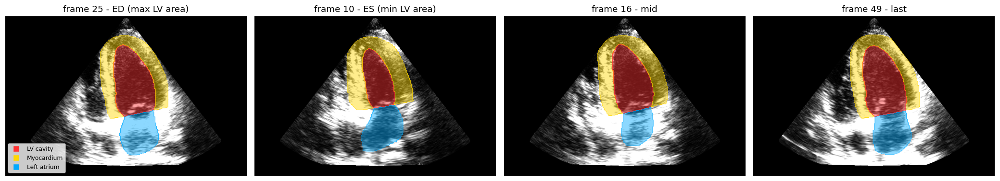

In [11]:
# ---- visual check: final three-structure result on four frames ----
def contour(ax, m, color, lw=1.6, ls='-'):
    if m.any(): ax.contour(m.astype(float), [0.5], colors=color, linewidths=lw, linestyles=ls)
def composite(k, gain=1.7):
    im = np.dstack([np.clip(P[k]*gain, 0, 255).astype(np.uint8)]*3).astype(float)
    for lab_, col in FILL.items():
        if avail[lab_]: sel = LAB[k] == lab_; im[sel] = 0.55*im[sel] + 0.45*np.array(col)
    im = im.astype(np.uint8)
    for lab_, col in FILL.items():
        if avail[lab_]:
            cnt, _ = cv2.findContours((LAB[k] == lab_).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE); cv2.drawContours(im, cnt, -1, col, 1)
    return im
area_lv = DF.loc[DF.clip_main, 'LV_area_px'].values.astype(float); idxs = np.arange(s0, s1)
area_s = savgol_filter(area_lv, 7, 2) if len(area_lv) >= 9 else area_lv
prom = 0.05*(area_s.max()-area_s.min())
ED, _ = find_peaks(area_s,  distance=6, prominence=prom); ES, _ = find_peaks(-area_s, distance=6, prominence=prom)
show = [idxs[ED[0]] if len(ED) else idxs[0], idxs[ES[0]] if len(ES) else idxs[len(idxs)//2], idxs[len(idxs)//3], idxs[-1]]
fig, ax = plt.subplots(1, 4, figsize=(19, 4.6))
for a, k, t in zip(ax, show, ['ED (max LV area)', 'ES (min LV area)', 'mid', 'last']): a.imshow(composite(k)); a.set_title(f'frame {k} - {t}'); a.axis('off')
for lab_, col in FILL.items():
    if avail[lab_]: ax[0].plot([], [], 's', color=np.array(col)/255, label=NAMES[lab_])
ax[0].legend(loc='lower left', fontsize=8); plt.tight_layout(); plt.show()

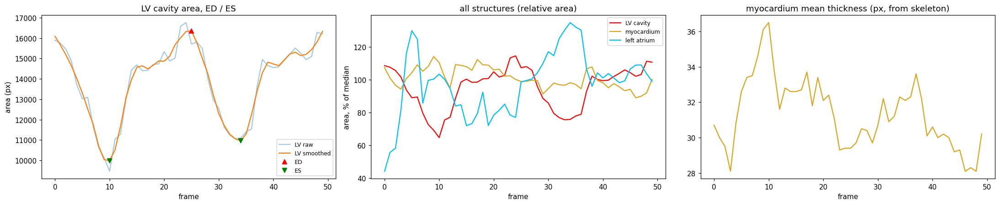

,ED_frame,ES_frame,LV_A_ED_px,LV_A_ES_px,LV_FAC_percent
0,25,34,16352,10966,32.9


LV FAC = (A_ED - A_ES)/A_ED from a 2-D area. It is NOT ejection fraction (EF needs Simpson biplane volumes + calibrated pixel size).
LA fractional area change over the clip = 71.2 %
correlation LV area vs LA area = -0.55  (physiology: the LA fills while the LV empties, so a NEGATIVE value is expected; positive/near 0 means check the LA mask)


In [12]:
# ---- measurements over the heartbeat ----
t = idxs / (FPS or 1); tlab = 'time (s)' if FPS else 'frame'
def series(col): return DF.loc[DF.clip_main, col].values.astype(float)
fig, ax = plt.subplots(1, 3, figsize=(20, 4.2))
ax[0].plot(t, area_lv, alpha=.4, label='LV raw'); ax[0].plot(t, area_s, label='LV smoothed'); ax[0].plot(t[ED], area_s[ED], 'r^', label='ED'); ax[0].plot(t[ES], area_s[ES], 'gv', label='ES')
ax[0].set_xlabel(tlab); ax[0].set_ylabel('area (px)'); ax[0].legend(fontsize=8); ax[0].set_title('LV cavity area, ED / ES')
norm = lambda x: 100*x/np.nanmedian(x)
ax[1].plot(t, norm(area_lv), color='red', label='LV cavity')
if avail[2]: ax[1].plot(t, norm(series('MYO_area_px')), color='goldenrod', label='myocardium')
if avail[3]: ax[1].plot(t, norm(series('LA_area_px')), color='deepskyblue', label='left atrium')
ax[1].set_xlabel(tlab); ax[1].set_ylabel('area, % of median'); ax[1].legend(fontsize=8); ax[1].set_title('all structures (relative area)')
if avail[2]: ax[2].plot(t, series('MYO_mean_thickness_px'), color='goldenrod'); ax[2].set_title('myocardium mean thickness (px, from skeleton)'); ax[2].set_xlabel(tlab)
else: ax[2].axis('off')
plt.tight_layout(); plt.show()

beats = []
for e in ED:
    nxt = [x for x in ES if x > e]
    if nxt: beats.append(dict(ED_frame=int(idxs[e]), ES_frame=int(idxs[nxt[0]]), LV_A_ED_px=round(area_s[e]), LV_A_ES_px=round(area_s[nxt[0]]), LV_FAC_percent=round(100*(area_s[e]-area_s[nxt[0]])/area_s[e], 1)))
BEATS = pd.DataFrame(beats); display(BEATS)
print('LV FAC = (A_ED - A_ES)/A_ED from a 2-D area. It is NOT ejection fraction (EF needs Simpson biplane volumes + calibrated pixel size).')
if avail[3]:
    la = series('LA_area_px'); la_s = savgol_filter(la, 7, 2) if len(la) >= 9 else la
    print('LA fractional area change over the clip = %.1f %%' % (100*(la_s.max()-la_s.min())/la_s.max()))
    if np.nanstd(la_s) > 0 and np.nanstd(area_s) > 0:
        r_ = np.corrcoef(area_s, la_s)[0, 1]; print('correlation LV area vs LA area = %.2f  (physiology: the LA fills while the LV empties, so a NEGATIVE value is expected; positive/near 0 means check the LA mask)' % r_)

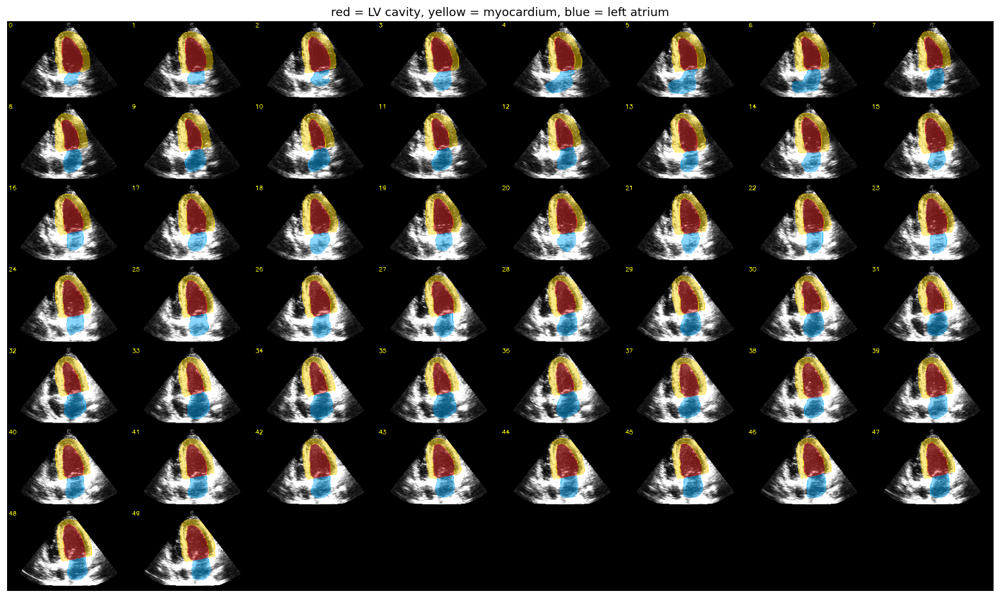

In [13]:
# ---- montage of every frame with the three structures ----
thumbs = []
for k in PROC_FRAMES:
    im = composite(k).copy(); cv2.putText(im, str(k), (8, 30), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 0), 2); thumbs.append(cv2.resize(im, (W//3, H//3)))
cols = 8; rows_ = int(np.ceil(len(thumbs)/cols)); thumbs += [np.zeros_like(thumbs[0])]*(rows_*cols-len(thumbs))
MONTAGE = np.vstack([np.hstack(thumbs[r*cols:(r+1)*cols]) for r in range(rows_)])
plt.figure(figsize=(18, 2.3*rows_)); plt.imshow(MONTAGE); plt.axis('off'); plt.title('red = LV cavity, yellow = myocardium, blue = left atrium'); plt.show()

## T. GLCM texture analysis (Haralick features) of the LV cavity, myocardium and left atrium
**What a GLCM is.** The *grey-level co-occurrence matrix* counts how often a pixel of grey level *i* has a neighbour of grey level *j* at a fixed distance and direction. Its shape describes the **texture** (speckle pattern) of a region: a smooth, uniform region concentrates the counts near the diagonal; a rough, high-contrast region spreads them far from it. Haralick features summarise the matrix in single numbers.

| Feature | What it measures | Typical reading here |
|---|---|---|
| **Contrast** | Σ P(i,j)·(i−j)² — weight of large grey differences between neighbours | high = coarse, strongly varying speckle |
| **Dissimilarity** | Σ P(i,j)·\|i−j\| — like contrast, grows linearly | high = rough |
| **Homogeneity** (IDM) | Σ P(i,j) / (1+(i−j)²) — closeness to the diagonal | high = smooth / uniform |
| **Energy** and **ASM** | Σ P(i,j)² — orderliness (energy = √ASM) | high = few dominant grey-level pairs (uniform) |
| **Correlation** | linear dependence between neighbouring grey levels | high = grey levels follow a pattern |
| **Entropy** | −Σ P·log₂P — randomness | high = disordered texture |

**How it is applied here (your professor's task)**
1. Input = the **original grey pixel values** (cleaned frame `P`, 0–255, *not* the denoised copy, because denoising would erase the speckle texture we want to measure).
2. For every frame and every structure (LV cavity, myocardium, left atrium) from stage F, the mask is **eroded by 3 px** so that edge pixels (partly belonging to a neighbour) do not contaminate the texture.
3. Grey values are quantised to **32 levels with one fixed global scale** (level 0 is reserved for "outside the region"), so features are comparable between structures and frames.
4. The GLCM is computed on the mask's bounding box for **4 directions (0°, 45°, 90°, 135°)** and **3 distances (1, 2, 4 px)**; every pair that touches a pixel outside the mask is **discarded**, so only texture *inside* the structure is measured. Features are averaged over the 4 directions. Distance 1 is the main result; the other distances show the texture *scale* (speckle size).
5. Outputs: a per-frame table, a summary per structure, a scale table, and three figures (the matrices themselves, a feature comparison between structures, and the features over the heartbeat).

**Reading the result (and its limits).** Blood (LV cavity, atrium) is dark with fine noise → usually *low contrast, high homogeneity/energy*; myocardium is brighter with real speckle → usually *higher contrast, lower energy*. Texture values depend on gain, depth, compression and the scanner, so **compare structures and frames inside this recording; do not compare absolute values between different machines or settings**. The numbers describe the texture of the *segmented region*: where the segmentation is doubtful (see stage F checks, especially the left atrium), the texture is doubtful too. A texture difference is not a diagnosis without clinical validation.

In [14]:
# ---- T1. GLCM texture features of every structure on every frame (original pixel values, inside the mask only) ----
import re
from skimage.feature import graycomatrix, graycoprops
_need = [n for n in ('LAB', 'P', 'PROC_FRAMES', 'NAMES', 'avail') if n not in globals()]
if _need: raise RuntimeError(f'Stage T needs {_need}: run stages A ... F first.')
GLCM_LEVELS     = globals().get('GLCM_LEVELS', 32)              # grey levels after quantisation (level 0 is reserved for "outside the region")
GLCM_DISTANCES  = globals().get('GLCM_DISTANCES', [1, 2, 4])    # pixel distances (1 = neighbours, 4 = speckle scale)
GLCM_ANGLES_DEG = globals().get('GLCM_ANGLES_DEG', [0, 45, 90, 135])
GLCM_MAIN_D     = globals().get('GLCM_MAIN_D', 1)               # distance used for the main tables/figures
GLCM_ERODE_PX   = globals().get('GLCM_ERODE_PX', 3)             # shrink each mask to avoid contaminated edge pixels
GLCM_MIN_PIXELS = globals().get('GLCM_MIN_PIXELS', 300)         # smaller regions are skipped (NaN)
GLCM_PROPS      = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'ASM', 'correlation']
assert GLCM_MAIN_D in GLCM_DISTANCES

def glcm_quantise(img):                                         # fixed global scale 0..255 -> levels 1..L-1 (0 = outside)
    return np.floor(np.clip(img, 0, 255) / 256.0 * (GLCM_LEVELS - 1)).astype(np.uint8) + 1

def eroded(mask):
    if GLCM_ERODE_PX <= 0: return mask
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*GLCM_ERODE_PX + 1, 2*GLCM_ERODE_PX + 1))
    return cv2.erode(mask.astype(np.uint8), k).astype(bool)

def glcm_stack(img, mask):
    """Normalised GLCMs (levels-1, levels-1, n_distances, n_angles) of the region only; pairs touching 'outside' are dropped."""
    ys, xs = np.where(mask)
    if ys.size < GLCM_MIN_PIXELS: return None
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    sub = np.where(mask[y0:y1, x0:x1], glcm_quantise(img[y0:y1, x0:x1]), 0).astype(np.uint8)
    M = graycomatrix(sub, GLCM_DISTANCES, np.deg2rad(GLCM_ANGLES_DEG), levels=GLCM_LEVELS, symmetric=True, normed=False)
    M = M[1:, 1:].astype(np.float64)                            # drop row/column 0 = every pair that touches a pixel outside the region
    tot = M.sum(axis=(0, 1), keepdims=True)
    if (tot < 50).any(): return None                            # too few valid pixel pairs
    return M / tot

def glcm_features(M):
    out = {}
    for p in GLCM_PROPS:
        v = graycoprops(M, p)                                   # (n_distances, n_angles)
        for j, d in enumerate(GLCM_DISTANCES): out[f'{p}_d{d}'] = float(v[j].mean())
    for j, d in enumerate(GLCM_DISTANCES):
        e = [-(M[..., j, a][M[..., j, a] > 0] * np.log2(M[..., j, a][M[..., j, a] > 0])).sum() for a in range(M.shape[3])]
        out[f'entropy_d{d}'] = float(np.mean(e))
    return out

GLCM_LABS = [k for k in (1, 2, 3) if avail[k]]
rows = []
for k in PROC_FRAMES:
    for lab_ in GLCM_LABS:
        m = eroded(LAB[k] == lab_); M = glcm_stack(P[k], m)
        r = dict(frame=int(k), structure=NAMES[lab_], n_pixels=int(m.sum()), mean_grey=round(float(P[k][m].mean()), 1) if m.any() else np.nan)
        r.update(glcm_features(M) if M is not None else {})
        rows.append(r)
GLCM_ALL = pd.DataFrame(rows)
GLCM_FEATS = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'ASM', 'correlation', 'entropy']
main_cols = {f'{f}_d{GLCM_MAIN_D}': f for f in GLCM_FEATS}
GLCM_DF = GLCM_ALL[['frame', 'structure', 'n_pixels', 'mean_grey'] + list(main_cols)].rename(columns=main_cols)       # main table (distance GLCM_MAIN_D)
GLCM_SUM = GLCM_DF.groupby('structure')[['mean_grey'] + GLCM_FEATS].agg(['mean', 'std']).round(3).reindex([NAMES[k] for k in GLCM_LABS])
sc = GLCM_ALL.melt(id_vars=['frame', 'structure'], value_vars=[c for c in GLCM_ALL.columns if re.search(r'_d\d+$', c)])
sc[['feature', 'distance']] = sc['variable'].str.extract(r'^(.*)_d(\d+)$'); sc['distance'] = sc['distance'].astype(int)
GLCM_SCALE = sc[sc.feature.isin(['contrast', 'homogeneity', 'energy', 'entropy'])].pivot_table(index=['structure', 'feature'], columns='distance', values='value', aggfunc='mean').round(3)
print(f'GLCM: {len(GLCM_LABS)} structures x {len(PROC_FRAMES)} frames | levels {GLCM_LEVELS-1} (+1 reserved) | distances {GLCM_DISTANCES} | angles {GLCM_ANGLES_DEG} | mask erosion {GLCM_ERODE_PX}px | main distance {GLCM_MAIN_D}')
print('frames with missing texture (region too small):', int(GLCM_DF[GLCM_FEATS].isna().any(axis=1).sum()))
print('\nSUMMARY per structure (mean and standard deviation over frames):'); display(GLCM_SUM)
print('TEXTURE SCALE (mean over frames) - how features change with pixel distance:'); display(GLCM_SCALE)

GLCM: 3 structures x 50 frames | levels 31 (+1 reserved) | distances [1, 2, 4] | angles [0, 45, 90, 135] | mask erosion 3px | main distance 1
frames with missing texture (region too small): 0

SUMMARY per structure (mean and standard deviation over frames):


mean_grey         contrast        dissimilarity         \
                 mean     std     mean    std          mean    std   
structure                                                            
LV cavity      21.186   5.840    1.808  0.496         0.785  0.182   
Myocardium    106.028  13.437    6.642  0.625         1.909  0.125   
Left atrium    89.394  34.856    4.544  1.115         1.510  0.207   

            homogeneity        energy           ASM        correlation         \
                   mean    std   mean    std   mean    std        mean    std   
structure                                                                       
LV cavity         0.692  0.066  0.348  0.115  0.134  0.088       0.894  0.025   
Myocardium        0.413  0.028  0.077  0.015  0.006  0.003       0.941  0.011   
Left atrium       0.494  0.039  0.110  0.026  0.013  0.006       0.933  0.011   

            entropy         
               mean    std  
structure                   
LV cavity     4.459  0.769  
Myocardium    7.954  0.172  
Left atrium   7.075  0.493

TEXTURE SCALE (mean over frames) - how features change with pixel distance:


distance                     1       2       4
structure   feature                           
LV cavity   contrast     1.808   2.771   6.685
            energy       0.348   0.330   0.300
            entropy      4.459   4.664   4.967
            homogeneity  0.692   0.640   0.551
Left atrium contrast     4.544   6.641  15.157
            energy       0.110   0.099   0.083
            entropy      7.075   7.368   7.881
            homogeneity  0.494   0.428   0.314
Myocardium  contrast     6.642  10.683  26.215
            energy       0.077   0.069   0.057
            entropy      7.954   8.281   8.844
            homogeneity  0.413   0.346   0.241

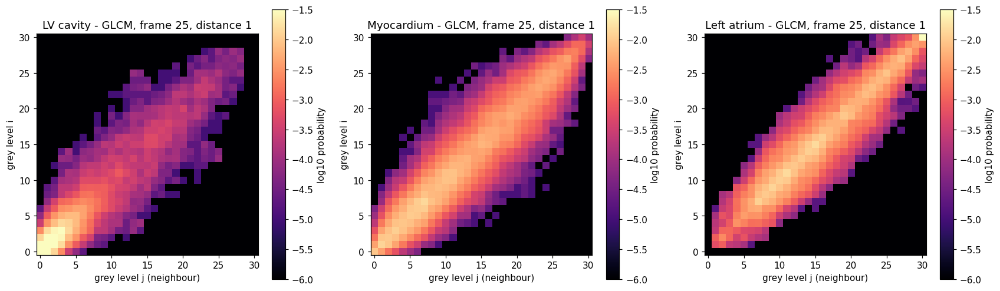

A tight bright diagonal = uniform texture. Mass far from the diagonal = strong grey differences between neighbours. The position along the diagonal shows the brightness.


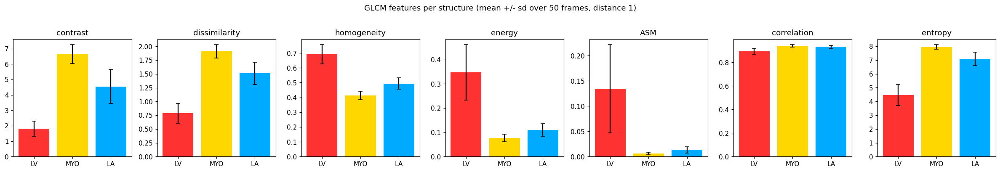

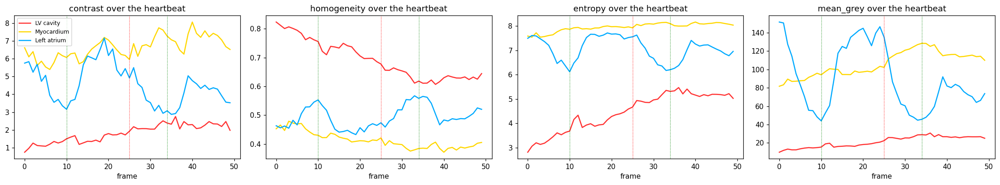

Dotted lines: red = end-diastole (max LV area), green = end-systole. Strong frame-to-frame jumps mean the mask (not the tissue) is changing.
READING: highest contrast -> Myocardium | most homogeneous -> LV cavity | most ordered (energy) -> LV cavity | highest entropy -> Myocardium
Expected for echo: blood (LV, atrium) smooth and dark; myocardium brighter with coarser speckle. If a structure deviates, check its mask in the stage F pictures first.


In [15]:
# ---- T2. Figures: the GLCMs themselves, feature comparison between structures, features over the heartbeat ----
GLCM_DIR = f'{WORK}/glcm_texture' if 'WORK' in globals() else '/content/glcm_texture'; shutil.rmtree(GLCM_DIR, ignore_errors=True); os.makedirs(GLCM_DIR)
COL = {NAMES[k]: np.array(FILL[k]) / 255 for k in GLCM_LABS}
k_ed = int(show[0]) if 'show' in globals() else int(PROC_FRAMES[0])
jd = GLCM_DISTANCES.index(GLCM_MAIN_D)

fig, ax = plt.subplots(1, len(GLCM_LABS), figsize=(5.2*len(GLCM_LABS), 4.6), squeeze=False)
for a, lab_ in zip(ax[0], GLCM_LABS):
    M = glcm_stack(P[k_ed], eroded(LAB[k_ed] == lab_))
    if M is None: a.set_title(f'{NAMES[lab_]}: region too small'); a.axis('off'); continue
    im = a.imshow(np.log10(M[..., jd, :].mean(-1) + 1e-6), cmap='magma', origin='lower', vmin=-6, vmax=-1.5)
    a.set_title(f'{NAMES[lab_]} - GLCM, frame {k_ed}, distance {GLCM_MAIN_D}'); a.set_xlabel('grey level j (neighbour)'); a.set_ylabel('grey level i'); plt.colorbar(im, ax=a, label='log10 probability')
plt.tight_layout(); plt.savefig(f'{GLCM_DIR}/glcm_matrices.png', dpi=130); plt.show()
print('A tight bright diagonal = uniform texture. Mass far from the diagonal = strong grey differences between neighbours. The position along the diagonal shows the brightness.')

fig, ax = plt.subplots(1, len(GLCM_FEATS), figsize=(3.1*len(GLCM_FEATS), 3.6))
for a, f in zip(ax, GLCM_FEATS):
    g = [GLCM_DF.loc[GLCM_DF.structure == NAMES[k], f].dropna().values for k in GLCM_LABS]
    a.bar(range(len(g)), [v.mean() if len(v) else np.nan for v in g], yerr=[v.std() if len(v) else 0 for v in g], color=[COL[NAMES[k]] for k in GLCM_LABS], capsize=3)
    a.set_xticks(range(len(g))); a.set_xticklabels([NAMES[k].replace('Left atrium', 'LA').replace('LV cavity', 'LV').replace('Myocardium', 'MYO') for k in GLCM_LABS]); a.set_title(f)
plt.suptitle(f'GLCM features per structure (mean +/- sd over {len(PROC_FRAMES)} frames, distance {GLCM_MAIN_D})', y=1.02); plt.tight_layout(); plt.savefig(f'{GLCM_DIR}/glcm_features_by_structure.png', dpi=130, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
for a, f in zip(ax, ['contrast', 'homogeneity', 'entropy', 'mean_grey']):
    for k in GLCM_LABS:
        d_ = GLCM_DF[GLCM_DF.structure == NAMES[k]]; a.plot(d_.frame, d_[f], color=COL[NAMES[k]], label=NAMES[k], lw=1.6)
    for e_ in (idxs[ED] if 'ED' in globals() and len(ED) else []): a.axvline(e_, color='r', ls=':', lw=.8)
    for e_ in (idxs[ES] if 'ES' in globals() and len(ES) else []): a.axvline(e_, color='g', ls=':', lw=.8)
    a.set_title(f'{f} over the heartbeat'); a.set_xlabel('frame')
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(f'{GLCM_DIR}/glcm_over_time.png', dpi=130); plt.show()
print('Dotted lines: red = end-diastole (max LV area), green = end-systole. Strong frame-to-frame jumps mean the mask (not the tissue) is changing.')

hi = lambda f, fn: (GLCM_SUM[(f, 'mean')].idxmax() if fn == 'max' else GLCM_SUM[(f, 'mean')].idxmin())
print(f"READING: highest contrast -> {hi('contrast', 'max')} | most homogeneous -> {hi('homogeneity', 'max')} | most ordered (energy) -> {hi('energy', 'max')} | highest entropy -> {hi('entropy', 'max')}")
print('Expected for echo: blood (LV, atrium) smooth and dark; myocardium brighter with coarser speckle. If a structure deviates, check its mask in the stage F pictures first.')

## G. Masks → ROI images with the **original pixel values** → extraction of LV, myocardium and left atrium
**Binary mask (what we had):** `M(x,y) = 1` inside the structure and `0` outside; saved as a picture the ROI is *white (255)* and the rest *black (0)*. It says *where* the structure is, but nothing about the tissue inside.

**Pixel-valued ROI (what the professor asked for):** the ROI keeps the **original ultrasound brightness**, everything else is 0:

&nbsp;&nbsp;&nbsp;&nbsp;`ROI(x,y) = I(x,y) · M(x,y)` &nbsp; i.e. &nbsp; `I(x,y)` if `M(x,y) = 1`, otherwise `0`

where `I` is the original frame. The **label map** `L(x,y) ∈ {0,1,2,3}` tells *which* structure each pixel belongs to (0 = background, **1 = LV cavity, 2 = myocardium, 3 = left atrium**), so `M_k = (L == k)`.

What this cell writes (all lossless PNG, same size as the frames):
| Folder | Content |
|---|---|
| **`masks_original_pixels/<structure>/`** | **THE MAIN RESULT:** the frame with only that structure's pixels kept (original values), black elsewhere |
| **`masks_original_pixels/All_regions/`** | the three structures together, each pixel with its original value |
| `rgba/<structure>/` | same pixels, but the outside is **transparent** (alpha = 0), so a real pixel value of 0 inside the ROI is not confused with background |
| `crops/<structure>/` | the same pixel-valued ROI **cut to the structure's bounding box** (one fixed box per structure, so every crop has the same size and can be stacked or fed to another program) |
| `label_maps/` | `labels_XXXX.png` (values 0–3, the identity of each region) and `labels_color_XXXX.png` (colour version for viewing) |
| `roi_pixels.npz` | arrays `gray` (frames × H × W, uint8 grey values) and `labels` (frames × H × W): `gray[labels == 1]` = all LV pixel values |
| `roi_intensity_stats.csv` | per frame and structure: pixel count, mean, std, min, quartiles, max of the grey values |

`SOURCE = 'original'` keeps the raw pixels of your PNG frames exactly (including the colour-mapped frames, which come from a different recording); `SOURCE = 'clean'` uses the grey frames with ECG/markers/text removed and the colour map undone, which makes the intensity numbers comparable across all 55 frames.

In [16]:
SOURCE = 'original'     # pixels used inside the ROIs: 'original' = raw pixels of your frames | 'clean' = ECG/markers removed, colour map undone
SAVE_CROPS = True       # also save each structure cut to its bounding box
SHOW_FRAMES = [int(k) for k in show]; MAIN_FRAMES = list(range(s0, s1))

In [17]:
import os, shutil
ROI_NAMES = {1: 'LV_cavity', 2: 'Myocardium', 3: 'Left_atrium'}
LABCOL = {1: (255, 50, 50), 2: (255, 215, 0), 3: (0, 170, 255)}          # colours used only for the *_color label maps
SOURCE = globals().get('SOURCE', 'original')                              # 'original' | 'clean'
assert SOURCE in ('original', 'clean'), "SOURCE must be 'original' or 'clean'"
OUT_ROI = '/content/roi_pixel_values'; shutil.rmtree(OUT_ROI, ignore_errors=True)
PRESENT = [k for k in ROI_NAMES if (LAB == k).any()]
print('structures present in the label maps:', {ROI_NAMES[k]: int((LAB == k).sum()) for k in PRESENT})
for k in PRESENT:
    for d in ('masks_original_pixels', 'rgba'): os.makedirs(f'{OUT_ROI}/{d}/{ROI_NAMES[k]}')
os.makedirs(f'{OUT_ROI}/masks_original_pixels/All_regions'); os.makedirs(f'{OUT_ROI}/label_maps')
SAVE_CROPS = globals().get('SAVE_CROPS', True)
CROP_BOX = {}
if SAVE_CROPS:                                                            # one fixed bounding box per structure (same size for every frame)
    for s in PRESENT:
        ys, xs = np.where((LAB == s).any(0)); CROP_BOX[s] = (int(max(xs.min()-4, 0)), int(max(ys.min()-4, 0)), int(min(xs.max()+5, W)), int(min(ys.max()+5, H)))
        os.makedirs(f'{OUT_ROI}/crops/{ROI_NAMES[s]}')

def source_rgb(k):
    if SOURCE == 'original': return RGB[k]                                # H x W x 3, uint8, exactly as stored in the PNG
    g = np.clip(P[k], 0, 255).astype(np.uint8); return np.dstack([g, g, g])
def gray_of(img): return cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)             # luminance = 0.299 R + 0.587 G + 0.114 B  (= the grey level for grey frames)
def keep_pixels(img, mask):                                               # ROI(x,y) = I(x,y) * M(x,y)
    out = np.zeros_like(img); out[mask] = img[mask]; return out
def save_rgb(path, img): cv2.imwrite(path, img[..., ::-1])
def save_rgba(path, img, mask): cv2.imwrite(path, cv2.cvtColor(np.dstack([img, (mask*255).astype(np.uint8)]), cv2.COLOR_RGBA2BGRA))

GRAYSTACK = np.zeros(LAB.shape, np.uint8); rows = []; preserved = True
for k in PROC_FRAMES:
    img = source_rgb(k); gray = gray_of(img); GRAYSTACK[k] = gray; lab = LAB[k]
    for s in PRESENT:
        m = lab == s; out = keep_pixels(img, m)
        preserved &= bool(np.array_equal(out[m], img[m]) and not out[~m].any())                 # inside = original, outside = 0
        if SAVE_CROPS: x1, y1, x2, y2 = CROP_BOX[s]; save_rgb(f'{OUT_ROI}/crops/{ROI_NAMES[s]}/{ROI_NAMES[s]}_{k:04d}.png', out[y1:y2, x1:x2])
        save_rgb(f'{OUT_ROI}/masks_original_pixels/{ROI_NAMES[s]}/{ROI_NAMES[s]}_{k:04d}.png', out); save_rgba(f'{OUT_ROI}/rgba/{ROI_NAMES[s]}/{ROI_NAMES[s]}_{k:04d}.png', out, m)
        v = gray[m]
        if v.size: rows.append(dict(frame=k, structure=ROI_NAMES[s], n_pixels=int(v.size), mean=round(float(v.mean()), 2), std=round(float(v.std()), 2), min=int(v.min()),
                                    p25=float(np.percentile(v, 25)), median=float(np.median(v)), p75=float(np.percentile(v, 75)), max=int(v.max())))
    union = np.isin(lab, PRESENT); save_rgb(f'{OUT_ROI}/masks_original_pixels/All_regions/All_regions_{k:04d}.png', keep_pixels(img, union))
    cv2.imwrite(f'{OUT_ROI}/label_maps/labels_{k:04d}.png', lab)
    colr = np.zeros(img.shape, np.uint8)
    for s in PRESENT: colr[lab == s] = LABCOL[s]
    save_rgb(f'{OUT_ROI}/label_maps/labels_color_{k:04d}.png', colr)

STATS = pd.DataFrame(rows); STATS.to_csv(f'{OUT_ROI}/roi_intensity_stats.csv', index=False)
np.savez_compressed(f'{OUT_ROI}/roi_pixels.npz', gray=GRAYSTACK, labels=LAB, frames_processed=np.array(PROC_FRAMES), label_names=np.array(['background', 'LV_cavity', 'Myocardium', 'Left_atrium']))
open(f'{OUT_ROI}/README.txt', 'w').write(
    "ROI images with ORIGINAL pixel values\n=====================================\n"
    "ROI(x,y) = I(x,y) * M(x,y): the pixels of a structure keep their original value, every other pixel is 0.\n"
    "Label map values: 0 background, 1 LV cavity, 2 myocardium, 3 left atrium.\n"
    f"Pixel source: {SOURCE} ({'raw PNG frames' if SOURCE == 'original' else 'grey frames with ECG/markers/text removed and the colour map undone'}).\n"
    "masks_original_pixels/: black outside the ROI. rgba/: transparent outside the ROI. crops/: ROI cut to the structure's bounding box. roi_pixels.npz: gray[labels==k] gives the pixel values of structure k.\n")
print(f'pixel-preservation check (inside ROI == original, outside == 0, every frame and structure): {"PASSED" if preserved else "FAILED"}')
print(f'processed frames: {PROC_FRAMES[0]}-{PROC_FRAMES[-1]} ({len(PROC_FRAMES)} frames) | written {sum(len(f) for _, _, f in os.walk(OUT_ROI))} files to {OUT_ROI}')

structures present in the label maps: {'LV_cavity': 695165, 'Myocardium': 789400, 'Left_atrium': 468199}
pixel-preservation check (inside ROI == original, outside == 0, every frame and structure): PASSED
processed frames: 0-49 (50 frames) | written 603 files to /content/roi_pixel_values


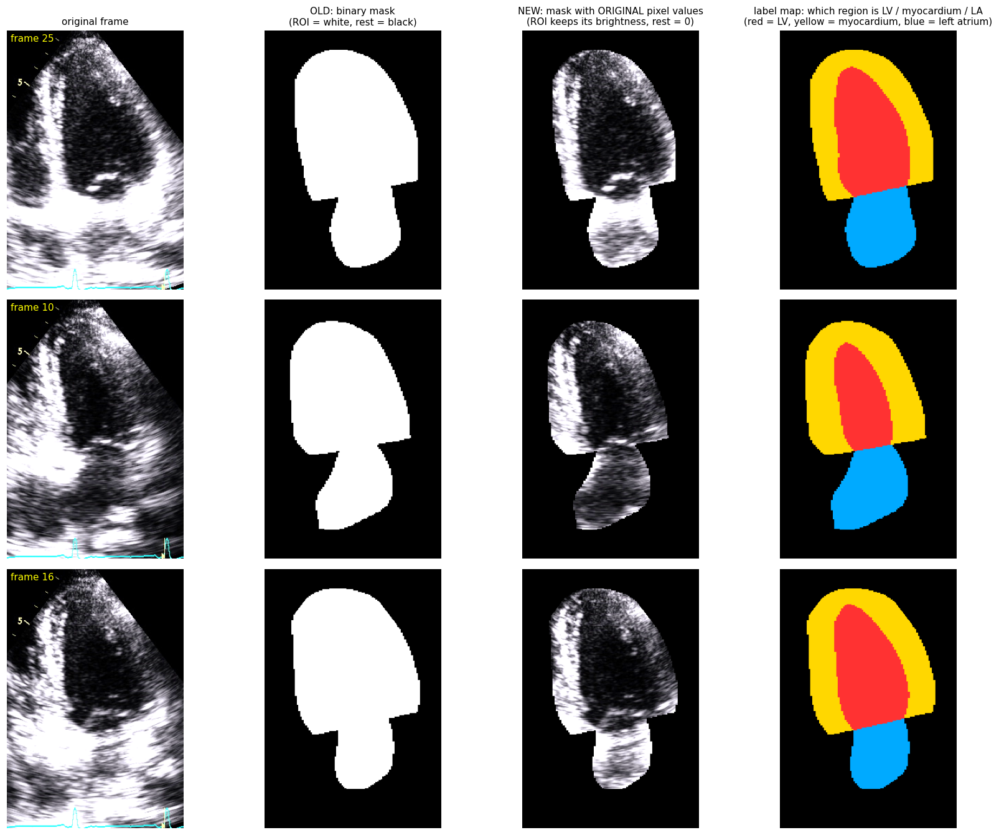

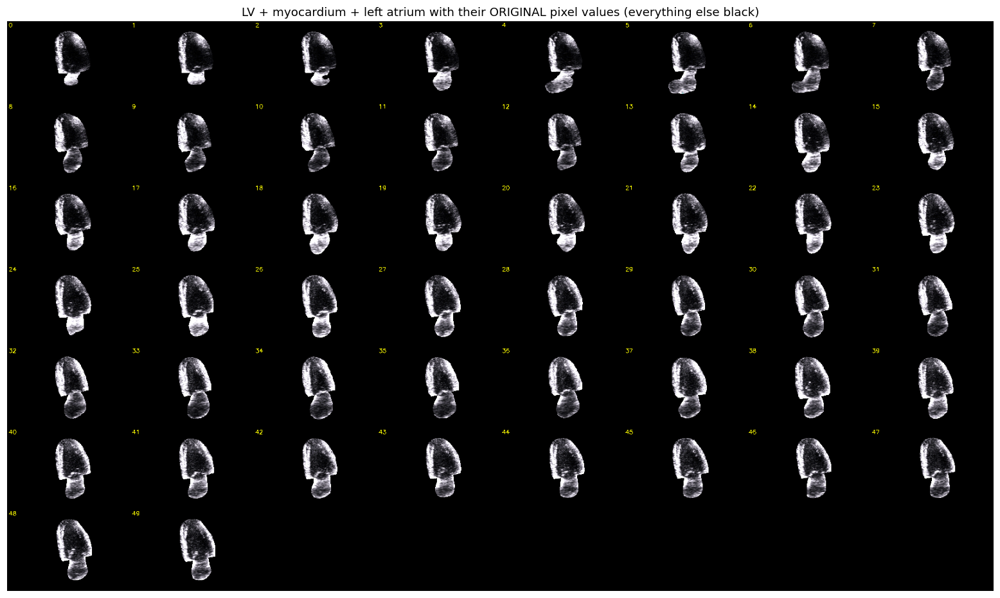

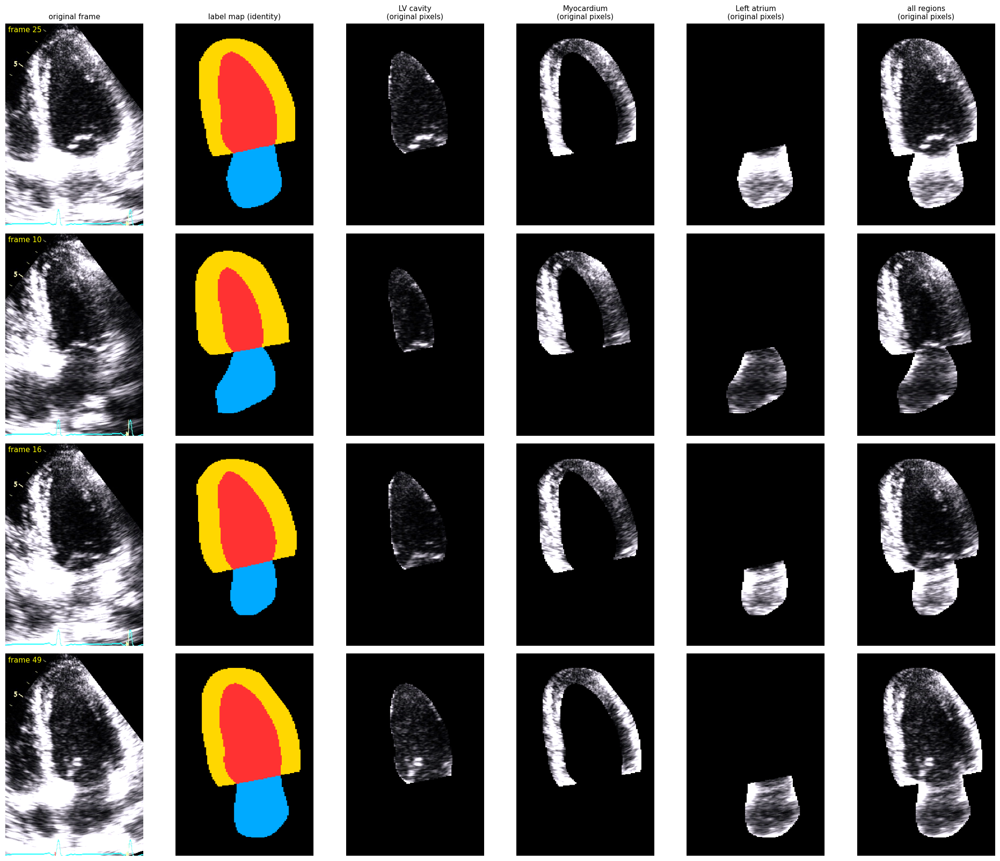

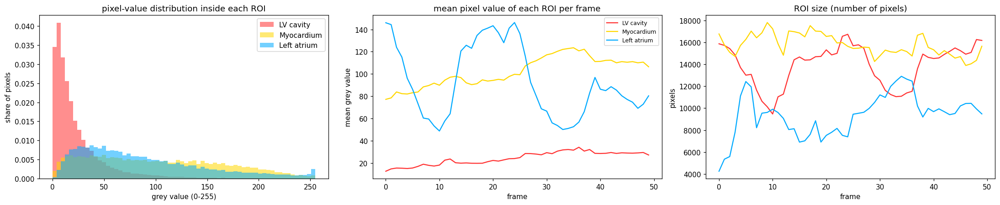

,mean_grey,std_inside_ROI,median_grey,mean_pixels
structure,,,,
LV_cavity,24.3,28.6,14.6,13903.3
Left_atrium,92.6,52.6,81.5,9364.0
Myocardium,102.0,62.6,94.6,15788.0


Expected: LV cavity and left atrium (blood) are DARK, the myocardium (muscle) is clearly BRIGHTER. If the order is different, check the masks.


In [18]:
# ---- THE POINT OF THIS STEP: old binary mask (ROI white) vs new mask (ROI keeps the original pixel values) ----
GAIN = 1.7        # display brightness only (the saved files are NOT changed)
ys_, xs_ = np.where((LAB > 0).any(0)); bx1, bx2, by1, by2 = max(xs_.min()-25, 0), min(xs_.max()+25, W), max(ys_.min()-25, 0), min(ys_.max()+25, H)
fig, ax = plt.subplots(len(SHOW_FRAMES[:3]), 4, figsize=(16, 4.1*len(SHOW_FRAMES[:3])), squeeze=False)
for r, k in enumerate(SHOW_FRAMES[:3]):
    img = source_rgb(k); u = np.isin(LAB[k], PRESENT)
    cl = np.zeros(img.shape, np.uint8)
    for s in PRESENT: cl[LAB[k] == s] = LABCOL[s]
    pan = [np.clip(img.astype(float)*GAIN, 0, 255).astype(np.uint8), np.dstack([u*255]*3).astype(np.uint8),
           np.clip(keep_pixels(img, u).astype(float)*GAIN, 0, 255).astype(np.uint8), cl]
    tt = ['original frame', 'OLD: binary mask\n(ROI = white, rest = black)', 'NEW: mask with ORIGINAL pixel values\n(ROI keeps its brightness, rest = 0)', 'label map: which region is LV / myocardium / LA\n(red = LV, yellow = myocardium, blue = left atrium)']
    for c_ in range(4):
        ax[r, c_].imshow(pan[c_][by1:by2, bx1:bx2]); ax[r, c_].axis('off')
        if r == 0: ax[r, c_].set_title(tt[c_], fontsize=10)
    ax[r, 0].text(5, 15, f'frame {k}', color='yellow', fontsize=10)
plt.tight_layout(); plt.show()

# ---- montage of ALL frames: each region with its original pixel values (saved too) ----
thumbs = []
for k in PROC_FRAMES:
    im = np.clip(keep_pixels(source_rgb(k), np.isin(LAB[k], PRESENT)).astype(float)*GAIN, 0, 255).astype(np.uint8).copy()
    cv2.putText(im, str(k), (8, 30), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 0), 2); thumbs.append(cv2.resize(im, (W//3, H//3)))
cols = 8; nrow = int(np.ceil(len(thumbs)/cols)); thumbs += [np.zeros_like(thumbs[0])]*(nrow*cols-len(thumbs))
MONTAGE_PIX = np.vstack([np.hstack(thumbs[r*cols:(r+1)*cols]) for r in range(nrow)])
cv2.imwrite(f'{OUT_ROI}/montage_masks_original_pixels.png', MONTAGE_PIX[..., ::-1])
plt.figure(figsize=(18, 2.3*nrow)); plt.imshow(MONTAGE_PIX); plt.axis('off'); plt.title('LV + myocardium + left atrium with their ORIGINAL pixel values (everything else black)'); plt.show()

# ---- look at it: original | label map | each structure with its ORIGINAL pixels | all three together ----
ys, xs = np.where((LAB > 0).any(0)); cx1, cx2, cy1, cy2 = max(xs.min()-25, 0), min(xs.max()+25, W), max(ys.min()-25, 0), min(ys.max()+25, H)
disp = lambda im: np.clip(im.astype(float)*GAIN, 0, 255).astype(np.uint8)[cy1:cy2, cx1:cx2]
titles = ['original frame', 'label map (identity)'] + [ROI_NAMES[s].replace('_', ' ') + '\n(original pixels)' for s in PRESENT] + ['all regions\n(original pixels)']
fig, ax = plt.subplots(len(SHOW_FRAMES), len(titles), figsize=(3.3*len(titles), 4.1*len(SHOW_FRAMES)), squeeze=False)
for r, k in enumerate(SHOW_FRAMES):
    img = source_rgb(k); lab = LAB[k]; colr = np.zeros(img.shape, np.uint8)
    for s in PRESENT: colr[lab == s] = LABCOL[s]
    panels = [disp(img), colr[cy1:cy2, cx1:cx2]] + [disp(keep_pixels(img, lab == s)) for s in PRESENT] + [disp(keep_pixels(img, np.isin(lab, PRESENT)))]
    for c_, (p_, t_) in enumerate(zip(panels, titles)):
        ax[r, c_].imshow(p_); ax[r, c_].axis('off')
        if r == 0: ax[r, c_].set_title(t_, fontsize=10)
    ax[r, 0].text(5, 15, f'frame {k}', color='yellow', fontsize=10)
plt.tight_layout(); plt.show()

# ---- what the pixel values tell us (main clip only: one recording, comparable grey levels) ----
S_ = STATS[STATS.frame.isin(MAIN_FRAMES)]
fig, ax = plt.subplots(1, 3, figsize=(20, 4.2)); palette = {ROI_NAMES[s]: np.array(LABCOL[s])/255 for s in PRESENT}
for s in PRESENT:
    vals = np.concatenate([GRAYSTACK[k][LAB[k] == s] for k in MAIN_FRAMES]); ax[0].hist(vals, bins=64, range=(0, 255), density=True, alpha=.55, color=palette[ROI_NAMES[s]], label=ROI_NAMES[s].replace('_', ' '))
    d = S_[S_.structure == ROI_NAMES[s]]; ax[1].plot(d.frame, d['mean'], color=palette[ROI_NAMES[s]], label=ROI_NAMES[s].replace('_', ' '))
    ax[2].plot(d.frame, d['n_pixels'], color=palette[ROI_NAMES[s]])
ax[0].set_xlabel('grey value (0-255)'); ax[0].set_ylabel('share of pixels'); ax[0].set_title('pixel-value distribution inside each ROI'); ax[0].legend()
ax[1].set_xlabel('frame'); ax[1].set_ylabel('mean grey value'); ax[1].set_title('mean pixel value of each ROI per frame'); ax[1].legend(fontsize=8)
ax[2].set_xlabel('frame'); ax[2].set_ylabel('pixels'); ax[2].set_title('ROI size (number of pixels)')
plt.tight_layout(); plt.show()
summary = S_.groupby('structure').agg(mean_grey=('mean', 'mean'), std_inside_ROI=('std', 'mean'), median_grey=('median', 'mean'), mean_pixels=('n_pixels', 'mean')).round(1)
display(summary)
print('Expected: LV cavity and left atrium (blood) are DARK, the myocardium (muscle) is clearly BRIGHTER. If the order is different, check the masks.')

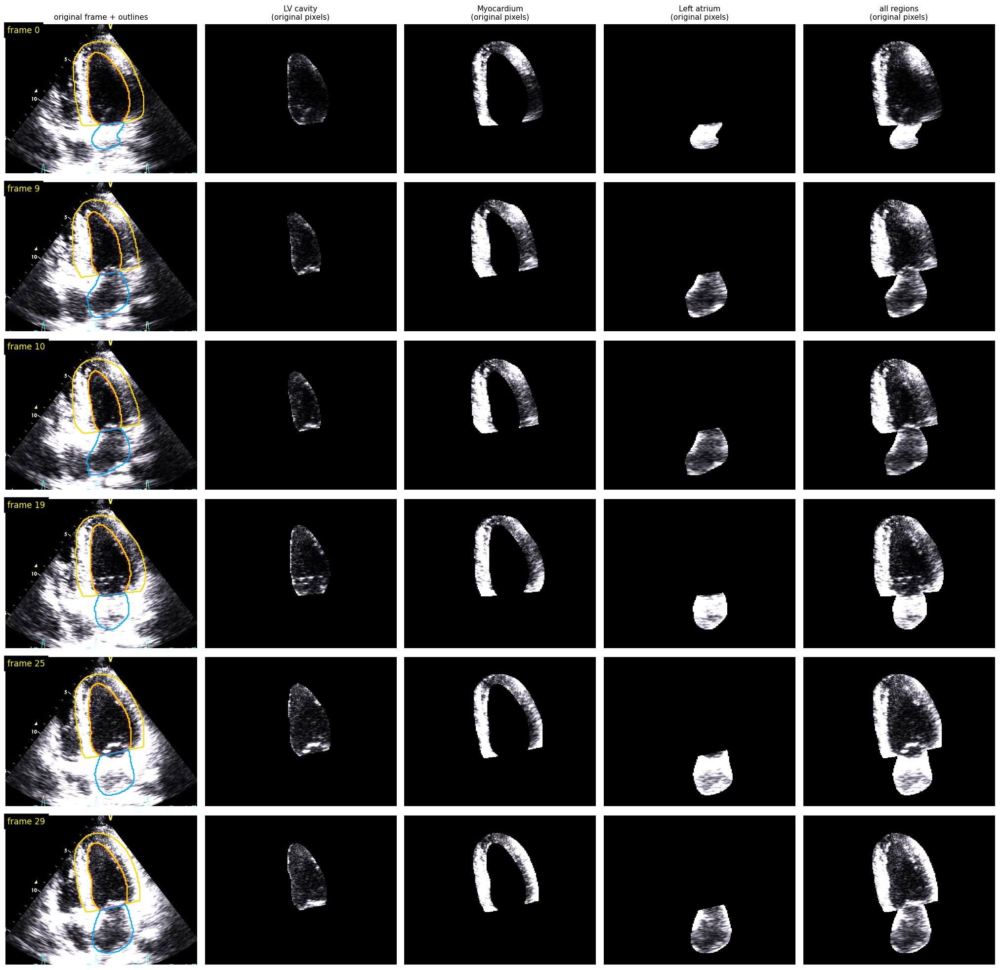

,share_of_frames_passing
LV_in_upper_half_of_fan,1.0
LA_below_LV,1.0
MYO_touches_LV,1.0
nothing_outside_fan,1.0


VIEW / ANATOMY CHECK: PASSED


In [19]:
# ---- VIEWS: every region in its OWN frame, same fan crop and same position as the original frame in every panel ----
os.makedirs(f'{OUT_ROI}/galleries', exist_ok=True)
vx1, vx2 = np.where(SM.any(0))[0][[0, -1]]; vy1, vy2 = np.where(SM.any(1))[0][[0, -1]]          # the fan area, identical crop for every panel
vcrop = lambda im: im[vy1:vy2+1, vx1:vx2+1]
VIEW_FRAMES = sorted(set([int(SHOW_FRAMES[0]), int(SHOW_FRAMES[1])] + [int(v) for v in np.linspace(s0, s1 - 1, 6)]))[:6]
VG = 2.2                                                                                          # display brightness only (saved files are NOT changed)
dispimg = lambda im: np.clip(im.astype(float)*VG, 0, 255).astype(np.uint8)
panel_titles = ['original frame + outlines'] + [ROI_NAMES[s].replace('_', ' ') + '\n(original pixels)' for s in PRESENT] + ['all regions\n(original pixels)']
fig, ax = plt.subplots(len(VIEW_FRAMES), len(panel_titles), figsize=(3.7*len(panel_titles), 3.0*len(VIEW_FRAMES)), squeeze=False)
for r, k in enumerate(VIEW_FRAMES):
    img = source_rgb(k); ov = dispimg(img).copy()
    for s in PRESENT:
        cnt, _ = cv2.findContours((LAB[k] == s).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE); cv2.drawContours(ov, cnt, -1, LABCOL[s], 2)
    ims = [ov] + [dispimg(keep_pixels(img, LAB[k] == s)) for s in PRESENT] + [dispimg(keep_pixels(img, np.isin(LAB[k], PRESENT)))]
    for c_, im in enumerate(ims):
        ax[r, c_].imshow(vcrop(im)); ax[r, c_].axis('off')
        if r == 0: ax[r, c_].set_title(panel_titles[c_], fontsize=10)
    ax[r, 0].text(5, 22, f'frame {k}', color='yellow', fontsize=11, backgroundcolor='black')
plt.tight_layout(); fig.savefig(f'{OUT_ROI}/galleries/views_each_region_in_its_own_frame.png', dpi=100, bbox_inches='tight'); plt.show()

# ---- automatic view / anatomy checks on every processed frame ----
def centroid(m): ys, xs = np.where(m); return (float(xs.mean()), float(ys.mean())) if len(xs) else (np.nan, np.nan)
fan_mid_y = (vy1 + vy2) / 2; chk = []
for k in PROC_FRAMES:
    lv, my, la = LAB[k] == 1, LAB[k] == 2, LAB[k] == 3; r = dict(frame=k)
    r['LV_in_upper_half_of_fan'] = bool(lv.any() and centroid(lv)[1] < fan_mid_y)
    if 3 in PRESENT: r['LA_below_LV'] = bool(la.any() and lv.any() and centroid(la)[1] > centroid(lv)[1])
    if 2 in PRESENT: r['MYO_touches_LV'] = bool(my.any() and lv.any() and cv2.dilate(lv.astype(np.uint8), np.ones((13, 13), np.uint8)).astype(bool)[my].any())
    r['nothing_outside_fan'] = bool(not (LAB[k][~SM] > 0).any()); chk.append(r)
VIEW_CHECK = pd.DataFrame(chk); share = VIEW_CHECK.drop(columns='frame').mean().round(2)
display(pd.DataFrame({'share_of_frames_passing': share}))
print('VIEW / ANATOMY CHECK:', 'PASSED' if (share >= 0.95).all() else 'ATTENTION - some frames fail: ' + ', '.join(share[share < 0.95].index) + '  (look at the picture above and at VIEW_CHECK)')
VIEW_CHECK.to_csv(f'{OUT_ROI}/view_anatomy_check.csv', index=False)

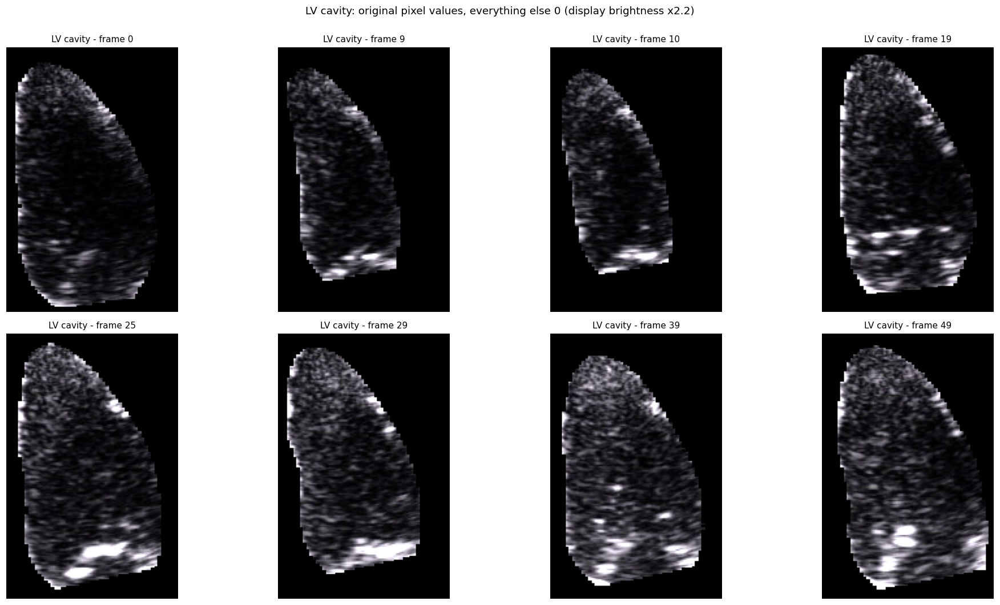

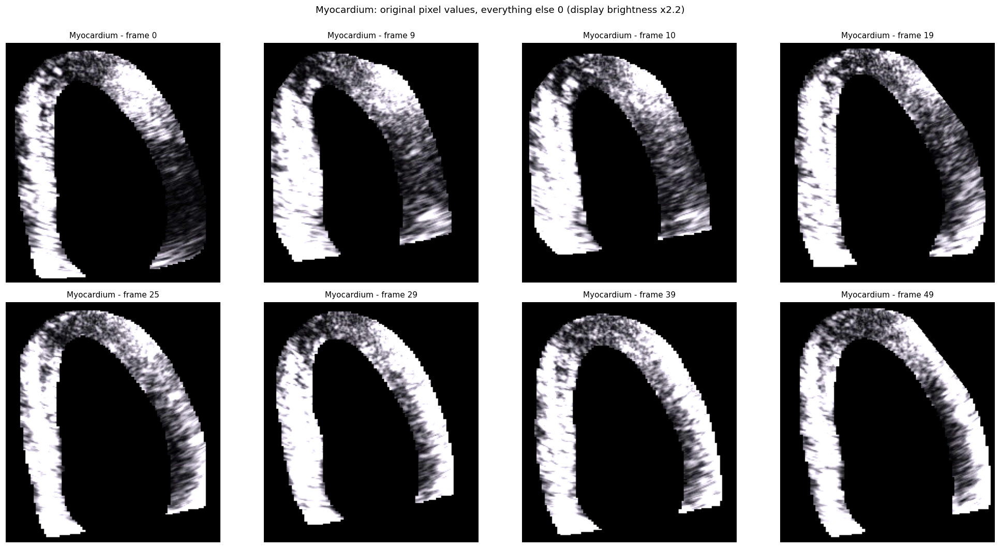

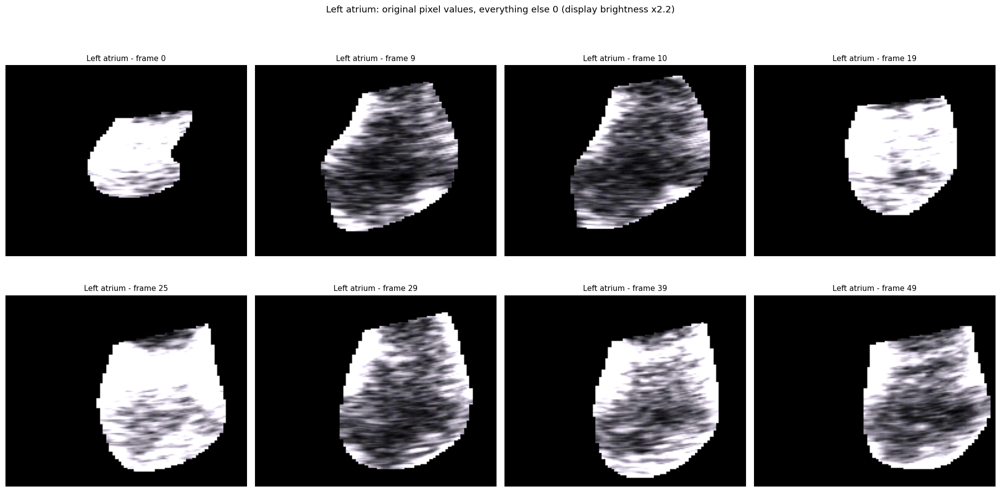

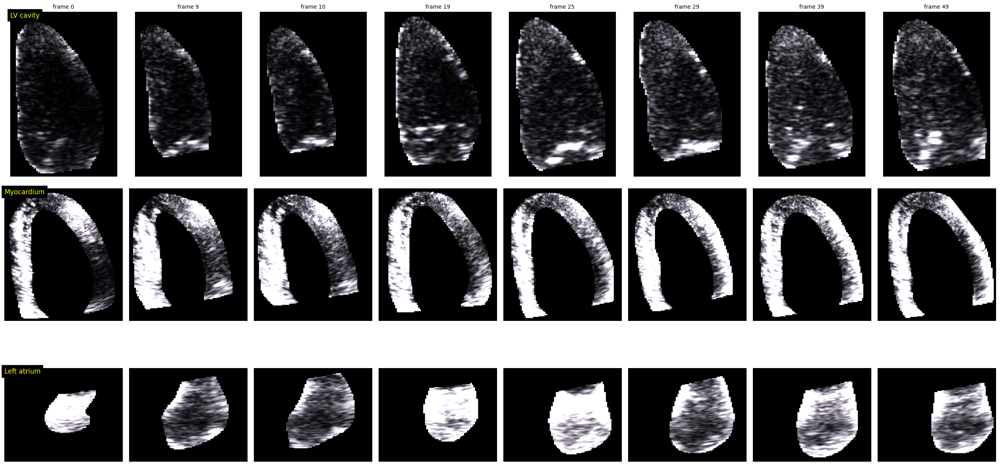

LV_cavity    stack (50, 204, 132) (frames x h x w) saved for frames 0-49, crop box x276-408, y69-273
Myocardium   stack (50, 232, 207) (frames x h x w) saved for frames 0-49, crop box x236-443, y44-276
Left_atrium  stack (50, 154, 194) (frames x h x w) saved for frames 0-49, crop box x227-421, y226-380


,structure,n_pixels,mean,std,near_black_pct,entropy_bits,median_edge_dist_px
0,LV_cavity,13903.3,24.3,28.6,22.5,3.0,85.2
1,Myocardium,15788.0,102.0,62.6,1.6,4.8,40.0
2,Left_atrium,9364.0,92.6,52.6,0.4,4.5,89.7


LEFT ATRIUM information check: PASSED (the region carries echo information and is away from the fan border)


In [20]:
# ---- SEPARATE FRAMES of each region (original pixel values), one gallery per structure ----
os.makedirs(f'{OUT_ROI}/galleries', exist_ok=True)
GAL = sorted(set([int(SHOW_FRAMES[0]), int(SHOW_FRAMES[1])] + [int(v) for v in np.linspace(s0, s1 - 1, 6)]))[:8]
GAIN_G = 2.2                                                   # display brightness only: the saved files are NOT changed
def region_crop(k, s):
    x1, y1, x2, y2 = CROP_BOX[s]; return keep_pixels(source_rgb(k), LAB[k] == s)[y1:y2, x1:x2]
show_g = lambda im: np.clip(im.astype(float)*GAIN_G, 0, 255).astype(np.uint8)
for s in PRESENT:
    ncol = 4; nrow = int(np.ceil(len(GAL)/ncol)); fig, ax = plt.subplots(nrow, ncol, figsize=(4.6*ncol, 4.8*nrow), squeeze=False)
    for a in ax.ravel(): a.axis('off')
    for a, k in zip(ax.ravel(), GAL): a.imshow(show_g(region_crop(k, s))); a.set_title(f'{ROI_NAMES[s].replace("_", " ")} - frame {k}', fontsize=10)
    fig.suptitle(f'{ROI_NAMES[s].replace("_", " ")}: original pixel values, everything else 0 (display brightness x{GAIN_G})', y=1.0); plt.tight_layout()
    fig.savefig(f'{OUT_ROI}/galleries/gallery_{ROI_NAMES[s]}.png', dpi=110, bbox_inches='tight'); plt.show()

# ---- all three structures, same frames, one picture ----
fig, ax = plt.subplots(len(PRESENT), len(GAL), figsize=(2.9*len(GAL), 3.9*len(PRESENT)), squeeze=False)
for r, s in enumerate(PRESENT):
    for c_, k in enumerate(GAL):
        ax[r, c_].imshow(show_g(region_crop(k, s))); ax[r, c_].axis('off')
        if r == 0: ax[r, c_].set_title(f'frame {k}', fontsize=9)
    ax[r, 0].text(0.0, 1.0, ROI_NAMES[s].replace('_', ' '), transform=ax[r, 0].transAxes, color='yellow', fontsize=11, va='top', backgroundcolor='black')
plt.tight_layout(); fig.savefig(f'{OUT_ROI}/galleries/gallery_all_structures.png', dpi=110, bbox_inches='tight'); plt.show()

# ---- EXTRACTION: stacks (frames x h x w, grey values inside the region, 0 outside) ----
os.makedirs(f'{OUT_ROI}/extracted_stacks', exist_ok=True)
for s in PRESENT:
    x1, y1, x2, y2 = CROP_BOX[s]
    st = np.stack([np.where(LAB[k] == s, GRAYSTACK[k], 0)[y1:y2, x1:x2] for k in PROC_FRAMES]).astype(np.uint8)
    np.save(f'{OUT_ROI}/extracted_stacks/{ROI_NAMES[s]}_stack.npy', st); np.save(f'{OUT_ROI}/extracted_stacks/frame_indices.npy', np.array(PROC_FRAMES))
    print(f'{ROI_NAMES[s]:12s} stack {st.shape} (frames x h x w) saved for frames {PROC_FRAMES[0]}-{PROC_FRAMES[-1]}, crop box x{x1}-{x2}, y{y1}-{y2}')

# ---- how much information does each region carry? ----
_rows = []
for s in PRESENT:
    st = [info_stats(LAB[k] == s, GRAYSTACK[k]) for k in MAIN_FRAMES if (LAB[k] == s).sum() > 50]
    _rows.append({'structure': ROI_NAMES[s], **{key: round(float(np.nanmean([d[key] for d in st])), 1) for key in ('n_pixels', 'mean', 'std', 'near_black_pct', 'entropy_bits', 'median_edge_dist_px')}})
INFO_TABLE = pd.DataFrame(_rows); display(INFO_TABLE); INFO_TABLE.to_csv(f'{OUT_ROI}/roi_information_check.csv', index=False)
if 3 in PRESENT:
    la = INFO_TABLE[INFO_TABLE.structure == 'Left_atrium'].iloc[0]
    ok = la['mean'] >= 30 and la['near_black_pct'] <= 12 and la['median_edge_dist_px'] >= 40
    print('LEFT ATRIUM information check:', 'PASSED (the region carries echo information and is away from the fan border)' if ok else
          'FAILED - the region is mostly dark/empty or hugs the fan border. Do not use the left atrium of this clip without checking it by eye')

## H. Save results

In [21]:
# ---- prerequisites: tell the user exactly which earlier cell has not been run (instead of a cryptic NameError) ----
_need = {'PROC_FRAMES': 'stage A2 (view check)', 'LAB': 'stage F (final masks)', 'DF': 'stage F (final masks)', 'avail': 'stage F (final masks)',
         'composite': 'stage F (visual check cell)', 'BEATS': 'stage F (cell "measurements over the heartbeat")', 'OUT_ROI': 'stage G (ROI extraction cell: "import os, shutil / ROI_NAMES")',
         'QC': 'stage F (sanity checks)'}
_missing = [f'  {k:12s} <- run {v}' for k, v in _need.items() if k not in globals()]
if _missing: raise RuntimeError('Some earlier cells have not been run (or failed). Run these first, then run this cell again:\n' + '\n'.join(_missing))
if not os.path.isdir(f'{OUT_ROI}/masks_original_pixels'): raise RuntimeError('Stage G did not produce the ROI images (folder masks_original_pixels is missing). Run the stage G cells again, then this cell.')
if 'MONTAGE' not in globals():                                    # the montage cell was skipped: build it here
    _th = []
    for k in PROC_FRAMES:
        im = composite(k).copy(); cv2.putText(im, str(k), (8, 30), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 0), 2); _th.append(cv2.resize(im, (W//3, H//3)))
    _c = 8; _r = int(np.ceil(len(_th)/_c)); _th += [np.zeros_like(_th[0])]*(_r*_c - len(_th))
    MONTAGE = np.vstack([np.hstack(_th[r*_c:(r+1)*_c]) for r in range(_r)]); print('montage rebuilt (its cell had not been run)')
TAG = 'promptfree_3structures'
OUT = f'/content/{TAG}_results'; shutil.rmtree(OUT, ignore_errors=True)
for d in ['labels', 'overlays'] + ([f'masks_{n}' for n in ('LV', 'MYO', 'LA')] if SAVE_BINARY_MASKS else []): os.makedirs(f'{OUT}/{d}')
for k in range(T_):
    cv2.imwrite(f'{OUT}/labels/labels_{k:04d}.png', LAB[k])                                   # 0 bg, 1 LV, 2 myocardium, 3 left atrium
    for lab_, n in ((1, 'LV'), (2, 'MYO'), (3, 'LA')):
        if SAVE_BINARY_MASKS and avail[lab_]: cv2.imwrite(f'{OUT}/masks_{n}/{n}_{k:04d}.png', (LAB[k] == lab_).astype(np.uint8)*255)
    cv2.imwrite(f'{OUT}/overlays/overlay_{k:04d}.png', composite(k)[..., ::-1])
cv2.imwrite(f'{OUT}/montage_all_frames.png', MONTAGE[..., ::-1])
DF.to_csv(f'{OUT}/per_frame_metrics.csv', index=False); BEATS.to_csv(f'{OUT}/beats_LV_FAC.csv', index=False)
QC.to_csv(f'{OUT}/sanity_checks.csv', index=False)
CITATION = '\n'.join(['Segmentation model: nnU-Net trained on CAMUS, from G. Van De Vyver, S. Thomas, G. Ben-Yosef, S. H. Olaisen, H. Dalen, L. Lovstakken, E. Smistad,',
    '"Towards Robust Cardiac Segmentation using Graph Convolutional Networks", IEEE Access, 2024, https://ieeexplore.ieee.org/document/10458930',
    'Paper repo (MIT; graph network + training code, not run here): https://github.com/GillesVanDeVyver/GCN_multistructure',
    'nnU-Net code (the method run here): https://github.com/MIC-DKFZ/nnUNet',
    'Weights (CC-BY-4.0, cite the paper): https://huggingface.co/gillesvdv/nnunet_camus_cv1_onnx',
    'nnU-Net: Isensee et al., Nature Methods 18:203-211 (2021)', 'CAMUS dataset: Leclerc et al., IEEE Trans. Med. Imaging 38(9), 2019', ''])
open(f'{OUT}/CITATION.txt', 'w').write(CITATION)
json.dump(dict(segmenter='PROMPT-FREE nnU-Net trained on CAMUS (Van De Vyver et al., IEEE Access 2024)', prompts_used='none (input = the grey frame only)',
               code='github.com/GillesVanDeVyver/GCN_multistructure', weights='huggingface.co/gillesvdv/nnunet_camus_cv1_onnx', input_variant=dict(normalisation=globals().get('PF_NORM'), flipped=bool(globals().get('PF_FLIP'))),
               label_values={'0': 'background', '1': 'LV cavity', '2': 'myocardium', '3': 'left atrium'}, processed_frames=[int(v) for v in PROC_FRAMES], process_clips=PROCESS_CLIPS,
               structures_available={NAMES[k]: bool(v) for k, v in avail.items()}, sanity_checks=QC.to_dict('records'),
               input_mode=INPUT_MODE, main_clip=[int(s0), int(s1)], n_frames=int(T_),
               glcm=(dict(levels=GLCM_LEVELS-1, distances=GLCM_DISTANCES, angles_deg=GLCM_ANGLES_DEG, main_distance=GLCM_MAIN_D, mask_erosion_px=GLCM_ERODE_PX) if 'GLCM_ALL' in globals() else 'not run')), open(f'{OUT}/run_summary.json', 'w'), indent=2, default=str)
if 'GLCM_ALL' in globals():                                       # stage T (GLCM texture analysis) was run
    os.makedirs(f'{OUT}/glcm_texture', exist_ok=True)
    GLCM_DF.to_csv(f'{OUT}/glcm_texture/glcm_per_frame_main_distance.csv', index=False); GLCM_ALL.to_csv(f'{OUT}/glcm_texture/glcm_per_frame_all_distances.csv', index=False)
    GLCM_SUM.to_csv(f'{OUT}/glcm_texture/glcm_summary_per_structure.csv'); GLCM_SCALE.to_csv(f'{OUT}/glcm_texture/glcm_scale_by_distance.csv')
    for f_ in glob.glob(f'{GLCM_DIR}/*.png'): shutil.copy(f_, f'{OUT}/glcm_texture/')
    open(f'{OUT}/glcm_texture/README.txt', 'w').write('\n'.join(['GLCM (grey-level co-occurrence matrix) texture features of LV cavity, myocardium, left atrium.',
        f'levels={GLCM_LEVELS-1} (+1 reserved for outside), distances={GLCM_DISTANCES}, angles={GLCM_ANGLES_DEG}, main distance={GLCM_MAIN_D}, mask erosion={GLCM_ERODE_PX}px.',
        'Input = original grey pixel values (not denoised). Pairs touching a pixel outside the mask are excluded. Features are averaged over the angles.',
        'Compare structures/frames inside this recording only; absolute values depend on gain, depth and scanner.', '']))
if os.path.isdir(OUT_ROI): shutil.copytree(OUT_ROI, f'{OUT}/ROI_pixel_values')
shutil.copytree(f'{OUT_ROI}/masks_original_pixels', f'{OUT}/masks_original_pixels')        # the MAIN result also at the top level of the zip
shutil.make_archive(OUT, 'zip', OUT); print(f'saved -> {OUT}.zip')
try:
    from google.colab import files; files.download(OUT + '.zip')
except ImportError: pass

saved -> /content/promptfree_3structures_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
if 'OUT' not in globals() or not os.path.isdir(OUT): raise RuntimeError('The save cell above did not finish. Fix its message first, run it again, then run this cell.')

# ---- what was produced ----
print('ONE zip with everything:', OUT + '.zip\n')
for d in sorted(os.listdir(OUT)):
    p = f'{OUT}/{d}'; n = sum(len(f) for _, _, f in os.walk(p)) if os.path.isdir(p) else 1
    print(f'  {d:26s} {n} file(s)')
if os.path.isdir(f'{OUT}/ROI_pixel_values'):
    print('\nInside ROI_pixel_values/:')
    for d in sorted(os.listdir(f'{OUT}/ROI_pixel_values')):
        p = f'{OUT}/ROI_pixel_values/{d}'; print(f'  {d}/' + ('  -> ' + ', '.join(sorted(os.listdir(p))[:4]) if os.path.isdir(p) else ''))
else: print('\n(ROI_pixel_values folder not found: run the save cell again)')
print('\nMAIN RESULT  masks_original_pixels/<LV_cavity | Myocardium | Left_atrium | All_regions>/  : ROI keeps its ORIGINAL pixel values, rest = 0')
print('Region identity (0 bg, 1 LV, 2 myocardium, 3 left atrium) : labels/')
print('Each region in its own frame: ROI_pixel_values/galleries/views_each_region_in_its_own_frame.png (+ one gallery per structure, + all three)')
print('View / anatomy check       : ROI_pixel_values/view_anatomy_check.csv | frames processed:', PROC_FRAMES[0], '-', PROC_FRAMES[-1])
print('Extraction                : ROI_pixel_values/crops, rgba (transparent outside), extracted_stacks (.npy), roi_pixels.npz, roi_intensity_stats.csv, roi_information_check.csv')
print('Segmenter                 : prompt-free nnU-Net (CAMUS), Van De Vyver et al. IEEE Access 2024 - see CITATION.txt')
print('Sanity checks             : sanity_checks.csv', '|', int((QC.status == 'WARN').sum()), 'WARN of', len(QC))
print('White binary masks were', 'ALSO saved (masks_LV/, masks_MYO/, masks_LA/)' if SAVE_BINARY_MASKS else 'NOT saved (SAVE_BINARY_MASKS = False)')


ONE zip with everything: /content/promptfree_3structures_results.zip

  CITATION.txt               1 file(s)
  ROI_pixel_values           615 file(s)
  beats_LV_FAC.csv           1 file(s)
  glcm_texture               8 file(s)
  labels                     55 file(s)
  masks_original_pixels      200 file(s)
  montage_all_frames.png     1 file(s)
  overlays                   55 file(s)
  per_frame_metrics.csv      1 file(s)
  run_summary.json           1 file(s)
  sanity_checks.csv          1 file(s)

Inside ROI_pixel_values/:
  README.txt/
  crops/  -> LV_cavity, Left_atrium, Myocardium
  extracted_stacks/  -> LV_cavity_stack.npy, Left_atrium_stack.npy, Myocardium_stack.npy, frame_indices.npy
  galleries/  -> gallery_LV_cavity.png, gallery_Left_atrium.png, gallery_Myocardium.png, gallery_all_structures.png
  label_maps/  -> labels_0000.png, labels_0001.png, labels_0002.png, labels_0003.png
  masks_original_pixels/  -> All_regions, LV_cavity, Left_atrium, Myocardium
  montage_masks_orig

## Troubleshooting
| Symptom | Fix |
|---|---|
| `NameError: name 'np' / 'P' is not defined` in P1 or P2 | The earlier stages were not run in this session. Run **A, A2, B** first, then P1, P2 (after *Restart runtime* run them all again) |
| P1 cannot download the model | Colab needs internet; try again, or set an `HF_TOKEN` secret if Hugging Face rate-limits you |
| The overlay shows swapped classes (e.g. myocardium and atrium exchanged) | Set `LABEL_REMAP = {0:0, 1:1, 2:3, 3:2}` (adapt to what you see) in P2 and run P2 again |
| The masks look shifted, mirrored or empty | Send me the output printed by P1 (input/output shapes, plausibility per variant, chosen variant) and a screenshot of the overlay |
| Stage F shows WARN lines | Look at the ED/ES pictures and the montage: WARN means the physical rule was not met (e.g. flicker, atrium in a bright region); the masks are still saved |
| LA area jumps at the first frames | The model segments each frame independently; the left atrium is the least stable structure. Report it as automatic but unvalidated |
| Stage G says `LEFT ATRIUM information check: FAILED` | The region is mostly dark/empty or hugs the fan border: do not use the left atrium of this clip without checking it by eye |
| Frames 50-54 are missing from the results | They are a different recording (see stage A2). Only the main clip is processed by default; `PROCESS_CLIPS = 'all'` forces all frames (unreliable) |
| `VIEW / ANATOMY CHECK: ATTENTION` | A region is in the wrong place in some frames: look at the stage-G views |
| GLCM table has empty (NaN) rows | The structure was smaller than `GLCM_MIN_PIXELS` (300 px after erosion) on that frame, usually the left atrium. Lower `GLCM_ERODE_PX` or `GLCM_MIN_PIXELS`, or check that mask in stage F |
| GLCM values jump between frames | The mask, not the tissue, is changing (see the stage F WARN lines). Texture of a wrong region is meaningless |
| Session was reset | Rerun every cell from the top |

**Citation (required by the weights licence):** G. Van De Vyver et al., *Towards Robust Cardiac Segmentation using Graph Convolutional Networks*, IEEE Access, 2024. https://ieeexplore.ieee.org/document/10458930